# Data Understanding and Preparation

In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.max_columns', None)

In [2]:
raw_data = pd.read_csv('data.csv')

In [3]:
raw_data.shape

(1263, 123)

In [4]:
raw_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1263 entries, 0 to 1262
Columns: 123 entries, nome_istituzione to 2024_Physical Sciences
dtypes: bool(1), float64(111), int64(2), object(9)
memory usage: 1.2+ MB


In [5]:
print(list(raw_data.columns))

['nome_istituzione', 'city', 'geonames_city_id', 'region', 'country_code', 'country', 'latitude', 'longitude', 'regione', 'macroarea', 'is_super_system', 'type', 'works_count_2026', 'oa_works_count_2026', 'cited_by_count_2026', 'works_count_2025', 'oa_works_count_2025', 'cited_by_count_2025', 'works_count_2024', 'oa_works_count_2024', 'cited_by_count_2024', 'works_count_2023', 'oa_works_count_2023', 'cited_by_count_2023', 'works_count_2022', 'oa_works_count_2022', 'cited_by_count_2022', 'works_count_2021', 'oa_works_count_2021', 'cited_by_count_2021', 'works_count_2020', 'oa_works_count_2020', 'cited_by_count_2020', 'works_count_2019', 'oa_works_count_2019', 'cited_by_count_2019', 'works_count_2018', 'oa_works_count_2018', 'cited_by_count_2018', 'works_count_2017', 'oa_works_count_2017', 'cited_by_count_2017', 'works_count_2016', 'oa_works_count_2016', 'cited_by_count_2016', 'works_count_2015', 'oa_works_count_2015', 'cited_by_count_2015', 'works_count_2014', 'oa_works_count_2014', 'ci

### Drop delle colonne che si sa già essere inutili

Per ridurre la quantità di dati da manipolare, droppiamo le colonne che abbiamo la certezza non saranno utili successivamente, ovvero tutte quelle con informazioni geografiche non pertinenti. Per adesso manteniamo la colonna con il nome istituzione.

In [6]:
# Eliminiamo oa_works_count
oa_cols = [col for col in raw_data.columns if 'oa_works_count' in str(col)]

In [7]:
columns_to_drop = ['geonames_city_id', 'region', 'country_code', 'country', 'longitude', 'latitude']
columns_to_drop.extend(oa_cols)

In [8]:
raw_data = raw_data.drop(columns = columns_to_drop)

Eliminiamo tutte le colonne che contengono riferimenti a lavori datati post 2024 e pre 2019.

In [9]:
def drop_works_count(df):
    for col in df.columns:
        string_col = str(col)
        if 'count' in string_col:
            parts = string_col.split(sep = '_')
            
            if 'works' in parts[0] and int(parts[2]) not in range(2019,2025):
                df = df.drop(columns = col)
    return df

In [10]:
new_df = drop_works_count(raw_data)

In [11]:
# Con questa funzione si eliminano le colonne appartenti alle categorie work_count
# e cited_by_count che risalgono a prima 2019 e post 2024
def drop_count(df):
    for col in df.columns:
        string_col = str(col)
        if 'count' in string_col:
            parts = string_col.split(sep = '_')

            if 'cited' in parts[0] and int(parts[3]) not in range(2019,2025):
                df = df.drop(columns = col)
    return df

In [12]:
df = drop_count(new_df)

In [13]:
# Molto più gestibile come dimensioni
df.columns

Index(['nome_istituzione', 'city', 'regione', 'macroarea', 'is_super_system',
       'type', 'works_count_2024', 'cited_by_count_2024', 'works_count_2023',
       'cited_by_count_2023', 'works_count_2022', 'cited_by_count_2022',
       'works_count_2021', 'cited_by_count_2021', 'works_count_2020',
       'cited_by_count_2020', 'works_count_2019', 'cited_by_count_2019',
       'roles', '2yr_mean_citedness', 'h_index', 'i10_index',
       'tot_dipendenti_per_anno_2019', 'studiosi_usciti_2019',
       'studiosi_entrati_2019', 'tot_dipendenti_per_anno_2020',
       'studiosi_usciti_2020', 'studiosi_entrati_2020',
       'tot_dipendenti_per_anno_2021', 'studiosi_usciti_2021',
       'studiosi_entrati_2021', 'tot_dipendenti_per_anno_2022',
       'studiosi_usciti_2022', 'studiosi_entrati_2022',
       'tot_dipendenti_per_anno_2023', 'studiosi_usciti_2023',
       'studiosi_entrati_2023', 'tot_dipendenti_per_anno_2024',
       'studiosi_usciti_2024', 'studiosi_entrati_2024', '2020_Health Scie

### Controllo duplicati

In [14]:
# Non ci sono duplicati, letsgo 
df.duplicated().value_counts()

False    1263
Name: count, dtype: int64

## Data Understanding features senza NaN

##### Regione

In [15]:
# Sbilanciata, ma ha senso che lo sia poiché regioni diverse hanno estensioni 
# diverse e non è una questione di mancanza dei dati ma strutturale. 
# Per questo non ci applicherei imbalanced learning ma la lascerei così.
regioni = df['regione'].value_counts()

In [16]:
top_n = 8

regioni_top = regioni.head(top_n)
altro = regioni.iloc[top_n:].sum()

regioni_grouped = regioni_top.copy()
regioni_grouped['Altro'] = altro


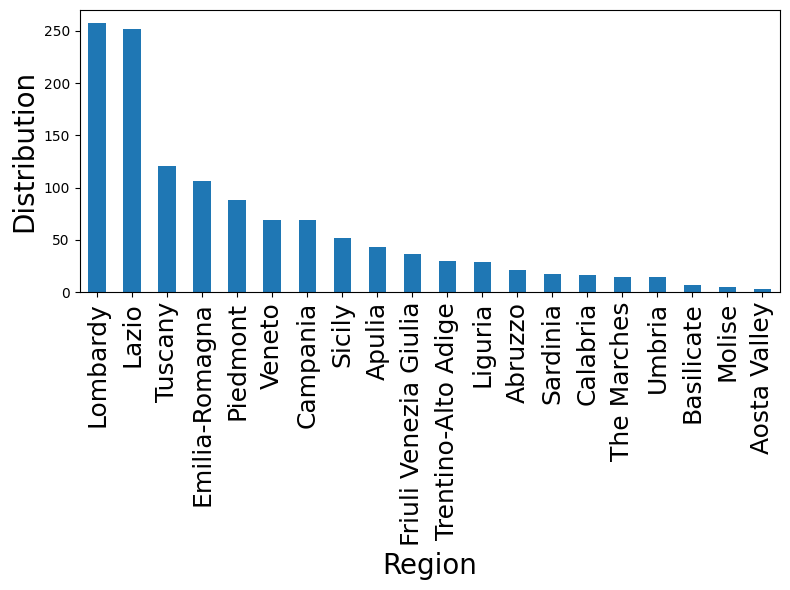

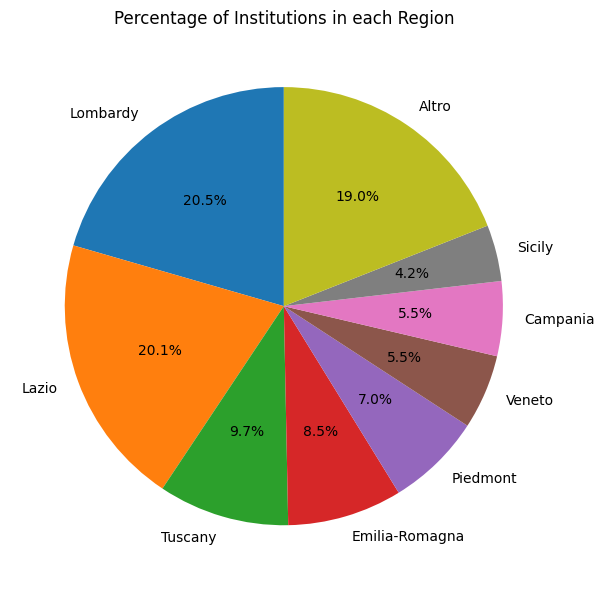

In [96]:
# Nonostante le regioni in 'altro' contengano valori molto bassi, comunque io manterrei ogni valore distinto
# Grafico 1: bar plot
plt.figure(figsize=(8,6))
regioni.plot(kind='bar')
plt.xlabel('Region', fontsize = 20)
plt.ylabel('Distribution', fontsize = 20)
plt.xticks(rotation=90, fontsize = 18)
plt.tight_layout()
plt.show()


# Grafico 2: pie chart
plt.figure(figsize=(8,6))
regioni_grouped.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    legend=False
)
plt.title('Percentage of Institutions in each Region')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [18]:
# Trasformiamo la variable tramite encoding
pd.get_dummies(df['regione'])

,Abruzzo,Aosta Valley,Apulia,Basilicate,Calabria,Campania,Emilia-Romagna,Friuli Venezia Giulia,Lazio,Liguria,Lombardy,Molise,Piedmont,Sardinia,Sicily,The Marches,Trentino-Alto Adige,Tuscany,Umbria,Veneto
0,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False
2,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1258,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1259,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1260,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1261,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


##### Macroarea

In [19]:
macroaree = df['macroarea'].value_counts()

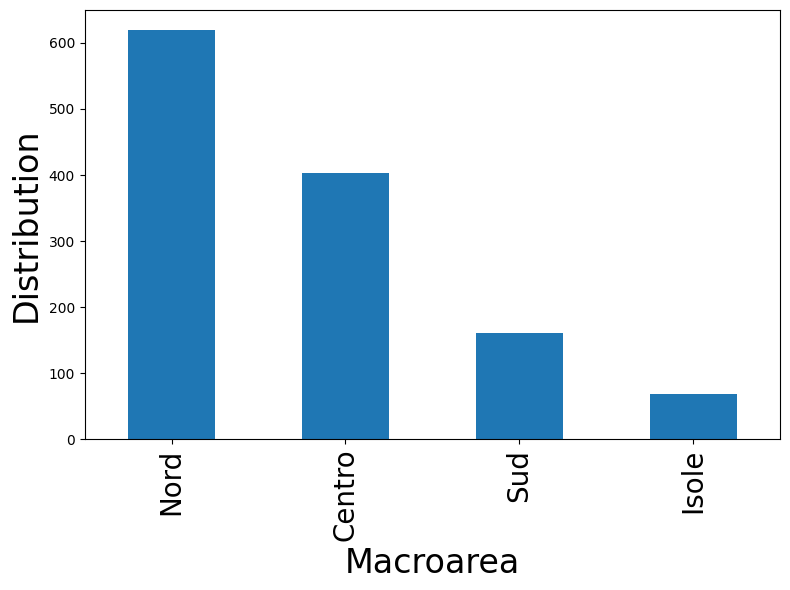

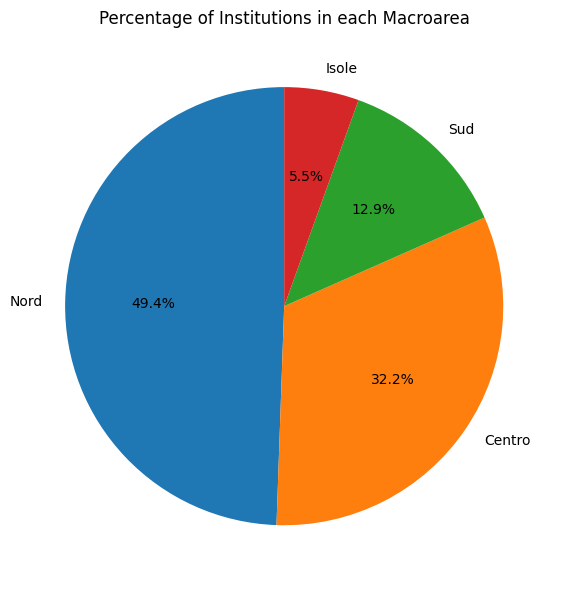

In [94]:
# Anche questa è sbilanciata, ma siccome riflette differenze strutturali la mantengo così
plt.figure(figsize=(8,6))
macroaree.plot(kind='bar')
plt.xlabel('Macroarea', fontsize = 24)
plt.ylabel('Distribution', fontsize = 24)
plt.xticks(rotation=90, fontsize = 20)
plt.tight_layout()
plt.show()


# Grafico 2: pie chart
plt.figure(figsize=(8,6))
macroaree.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    legend=False
)
plt.title('Percentage of Institutions in each Macroarea')
plt.ylabel('')
plt.tight_layout()
plt.show()

### Creiamo una mappa per la distribuzione

In [21]:
import geopandas as gpd
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import mapclassify

In [22]:
df

,nome_istituzione,city,regione,macroarea,is_super_system,type,works_count_2024,cited_by_count_2024,works_count_2023,cited_by_count_2023,works_count_2022,cited_by_count_2022,works_count_2021,cited_by_count_2021,works_count_2020,cited_by_count_2020,works_count_2019,cited_by_count_2019,roles,2yr_mean_citedness,h_index,i10_index,tot_dipendenti_per_anno_2019,studiosi_usciti_2019,studiosi_entrati_2019,tot_dipendenti_per_anno_2020,studiosi_usciti_2020,studiosi_entrati_2020,tot_dipendenti_per_anno_2021,studiosi_usciti_2021,studiosi_entrati_2021,tot_dipendenti_per_anno_2022,studiosi_usciti_2022,studiosi_entrati_2022,tot_dipendenti_per_anno_2023,studiosi_usciti_2023,studiosi_entrati_2023,tot_dipendenti_per_anno_2024,studiosi_usciti_2024,studiosi_entrati_2024,2020_Health Sciences,2020_Life Sciences,2020_Social Sciences,2020_Physical Sciences,2021_Health Sciences,2021_Life Sciences,2021_Social Sciences,2021_Physical Sciences,2022_Health Sciences,2022_Life Sciences,2022_Social Sciences,2022_Physical Sciences,2023_Health Sciences,2023_Life Sciences,2023_Social Sciences,2023_Physical Sciences,2024_Health Sciences,2024_Life Sciences,2024_Social Sciences,2024_Physical Sciences
0,Institute of Neurological Sciences,Mangone,Calabria,Sud,False,facility,108.0,491.0,117.0,960.0,94.0,2851.0,136.0,2447.0,152.0,6189.0,148.0,9442.0,['institution'],2.434053,246,8157,38.0,17.0,0.0,50.0,35.0,29.0,28.0,20.0,13.0,22.0,12.0,14.0,24.0,11.0,14.0,20.0,10.0,7.0,74.81,22.22,1.48,1.48,73.04,21.74,4.35,0.87,70.37,19.75,8.64,1.23,63.27,29.59,4.08,3.06,65.71,23.81,5.71,4.76
1,University of Siena,Siena,Tuscany,Centro,False,education,3182.0,13814.0,3034.0,21889.0,2844.0,40025.0,2662.0,53416.0,2719.0,75996.0,2367.0,62857.0,"['funder', 'institution']",2.391423,521,79249,415.0,73.0,0.0,394.0,63.0,52.0,400.0,77.0,69.0,398.0,102.0,75.0,438.0,151.0,142.0,349.0,93.0,62.0,45.11,17.44,14.16,23.30,43.66,17.15,16.17,23.02,44.97,17.19,13.95,23.89,42.75,16.65,15.60,25.01,45.32,15.95,15.75,22.97
2,IRCCS Ospedale San Raffaele,Milan,Lombardy,Nord,False,healthcare,1625.0,8190.0,1629.0,16301.0,1426.0,34961.0,1270.0,38226.0,1163.0,49243.0,823.0,33937.0,['institution'],2.573100,375,21726,297.0,140.0,0.0,280.0,90.0,123.0,376.0,130.0,186.0,385.0,141.0,139.0,425.0,210.0,181.0,313.0,126.0,98.0,82.78,13.71,2.00,1.50,79.04,17.56,1.42,1.98,73.76,21.86,2.36,2.03,75.72,19.89,2.48,1.92,72.41,23.45,1.57,2.57
3,Bambino Gesù Children's Hospital,Rome,Lazio,Centro,False,healthcare,1851.0,8472.0,1627.0,14612.0,1804.0,31688.0,1686.0,39876.0,1542.0,55282.0,1138.0,36549.0,['institution'],3.008373,344,32288,241.0,34.0,0.0,232.0,28.0,25.0,231.0,28.0,27.0,244.0,59.0,41.0,209.0,32.0,24.0,215.0,46.0,38.0,66.37,28.78,2.15,2.70,65.48,28.03,4.12,2.37,66.84,27.35,3.90,1.92,69.99,25.60,2.28,2.13,69.21,25.67,2.96,2.16
4,University of Florence,Florence,Tuscany,Centro,False,education,8270.0,32069.0,7698.0,66448.0,7750.0,100752.0,7537.0,131602.0,7306.0,173527.0,6296.0,157989.0,"['funder', 'institution', 'publisher']",2.219095,693,175189,1125.0,161.0,0.0,1141.0,219.0,177.0,1098.0,189.0,176.0,1083.0,205.0,174.0,1043.0,210.0,165.0,949.0,222.0,116.0,32.44,17.50,15.44,34.62,31.94,17.75,15.81,34.51,32.98,16.92,16.39,33.72,33.15,15.82,16.33,34.70,31.83,14.80,17.52,35.85
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1258,Ospedale Pediatrico Giovanni XXIII,Bari,NaN,NaN,False,healthcare,158.0,580.0,167.0,1308.0,182.0,1749.0,152.0,2241.0,145.0,4627.0,71.0,1421.0,['institution'],2.067701,98,1540,17.0,9.0,0.0,21.0,10.0,13.0,24.0,10.0,13.0,18.0,1.0,4.0,29.0,13.0,12.0,26.0,16.0,10.0,75.86,18.97,2.59,2.59,80.33,13.93,3.28,2.46,74.36,21.79,2.56,1.28,77.54,19.57,1.45,1.45,77.54,16.67,2.90,2.90
1259,Ospedale San Bortolo,Vicenza,NaN,NaN,False,healthcare,312.0,1537.0,328.0,3031.0,312.0,2998.0,280.0,4931.0,280.0,7011.0,255.0,12609.0,['institution'],

In [23]:
mapping_regioni = {
    "Lombardy": "Lombardia",
    "Lazio": "Lazio",
    "Tuscany": "Toscana",
    "Emilia-Romagna": "Emilia-Romagna",
    "Piedmont": "Piemonte",
    "Veneto": "Veneto",
    "Campania": "Campania",
    "Sicily": "Sicilia",
    "Apulia": "Puglia",
    "Friuli Venezia Giulia": "Friuli-Venezia Giulia",
    "Trentino-Alto Adige": "Trentino-Alto Adige/Südtirol",
    "Liguria": "Liguria",
    "Abruzzo": "Abruzzo",
    "Sardinia": "Sardegna",
    "Calabria": "Calabria",
    "The Marches": "Marche",
    "Umbria": "Umbria",
    "Basilicata": "Basilicata",
    "Molise": "Molise",
    "Aosta Valley": "Valle d'Aosta/Vallée d'Aoste"
}

# Applica la mappatura al tuo dataframe
df['regione_it'] = df['regione'].map(mapping_regioni)

In [24]:
# import matplotlib.pyplot as plt
# import matplotlib.patches as mpatches
# from matplotlib.patches import Patch
# from matplotlib.lines import Line2D
# import geopandas as gpd
# import mapclassify
# import numpy as np

# # 2. --- FILTER & CLEAN DATA ---
# df['regione_it'] = df['regione'].map(mapping_regioni)
# df_clean = df.dropna(subset=['city', 'regione_it', 'latitude', 'longitude']).copy()

# # ✅ FIX 1: Rimuovi coordinate fuori dall'Italia (bounding box Italia)
# df_clean = df_clean[
#     (df_clean['latitude'].between(35.0, 48.0)) &
#     (df_clean['longitude'].between(6.0, 19.0))
# ]

# # Conteggio per città
# city_counts = df_clean.groupby(
#     ['city', 'regione_it', 'latitude', 'longitude']
# ).size().reset_index(name='count')

# gdf_cities = gpd.GeoDataFrame(
#     city_counts,
#     geometry=gpd.points_from_xy(city_counts.longitude, city_counts.latitude),
#     crs='EPSG:4326'
# )

# # 3. --- CARICAMENTO GEOJSON REGIONI ---
# regions = gpd.read_file(
#     "https://raw.githubusercontent.com/openpolis/geojson-italy/master/geojson/limits_IT_regions.geojson"
# )

# # Conteggio per regione
# region_counts = df_clean.groupby('regione_it').size().reset_index(name='count')
# regions = regions.merge(region_counts, left_on='reg_name', right_on='regione_it', how='left')
# regions['count'] = regions['count'].fillna(0)

# # ✅ FIX 2: Riproietta tutto in Web Mercator per una resa corretta
# regions = regions.to_crs('EPSG:3857')
# gdf_cities = gdf_cities.to_crs('EPSG:3857')

# regions_nonzero = regions[regions['count'] > 0].copy()
# regions_zero = regions[regions['count'] == 0].copy()

# # 4. --- CLASSIFICAZIONE COLORI ---
# if not regions_nonzero.empty:
#     scheme = mapclassify.NaturalBreaks(
#         regions_nonzero['count'], 
#         k=min(5, len(regions_nonzero['count'].unique()))
#     )
#     regions_nonzero = regions_nonzero.copy()
#     regions_nonzero.loc[:, 'class'] = scheme.yb
#     max_class = regions_nonzero['class'].max()
#     cmap = plt.get_cmap('GnBu')

# # 5. --- PLOTTING ---
# fig, ax = plt.subplots(figsize=(10, 16))

# # Disegna regioni con dati
# if not regions_nonzero.empty:
#     regions_nonzero.plot(
#         ax=ax, column='class', cmap='GnBu',
#         edgecolor='gray', linewidth=0.5, alpha=0.9
#     )

# # Disegna regioni senza dati
# regions_zero.plot(ax=ax, color='#f0f0f0', edgecolor='gray', linewidth=0.5)

# # Disegna i pallini delle città
# circles_color = '#e67e22'
# gdf_cities.plot(
#     ax=ax,
#     markersize=gdf_cities['count'] * 25 + 25,
#     color=circles_color, alpha=0.6,
#     edgecolor='white', linewidth=0.7
# )

# # ✅ FIX 3: Imposta il bounding box sull'Italia (in EPSG:3857)
# # Coordinate Italia: lon 6-19, lat 35-48 → convertite in metri
# from pyproj import Transformer
# transformer = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
# x_min, y_min = transformer.transform(6.0, 35.0)
# x_max, y_max = transformer.transform(19.0, 48.0)

# ax.set_xlim(x_min, x_max)
# ax.set_ylim(y_min, y_max)
# ax.axis('off')

# # ✅ FIX 4: Forza l'aspect ratio corretto
# ax.set_aspect('equal')

# # --- LEGENDE ---

# # 1. Legenda Regioni (Choropleth)
# region_patches = [Patch(facecolor='#f0f0f0', edgecolor='gray', label='0 Institutions')]
# if not regions_nonzero.empty:
#     upper_bounds = scheme.bins
#     for i, bound in enumerate(upper_bounds):
#         lower = upper_bounds[i-1] + 1 if i > 0 else int(regions_nonzero['count'].min())
#         color = cmap(i / max_class) if max_class > 0 else cmap(0)
#         region_patches.append(Patch(
#             facecolor=color,
#             edgecolor='gray',
#             label=f"{int(lower)}–{int(bound)}"
#         ))

# legend1 = ax.legend(
#     handles=region_patches,
#     title='Institutions by Region',
#     title_fontsize=10,
#     loc='upper left',
#     bbox_to_anchor=(0.72, 1.0),
#     bbox_transform=ax.transAxes,
#     frameon=False, fontsize=9,
#     handlelength=1.2,
#     handletextpad=0.5,
#     labelspacing=0.3
# )
# ax.add_artist(legend1)
# # 2. Legenda Città (Pallini)
# circle_sizes = [1, 10, 50]
# circle_legend_items = [
#     Line2D([0], [0], marker='o', linestyle='',
#            markersize=(n * 25 + 25) ** 0.5,
#            markerfacecolor=circles_color,
#            markeredgecolor='white', alpha=0.7,
#            label=f'{n} Istitutio{"n" if n == 1 else "ns"}')
#     for n in circle_sizes
# ]

# legend2 = ax.legend(
#     handles=circle_legend_items,
#     title='Institutions by City',
#     title_fontsize=10,
#     loc='upper left',
#     bbox_to_anchor=(0.72, 0.80),
#     bbox_transform=ax.transAxes,
#     frameon=False, fontsize=9,
#     handlelength=1.2,
#     handletextpad=1.5,
#     labelspacing=2.0
# )
# # Invece di plt.tight_layout(), usa:
# fig.subplots_adjust(right=0.75)
# plt.show()

In [25]:
df = df.drop('regione_it', axis=1)

##### City

In [26]:
# Ci sono 262 città diverse: la granularità è davvero profonda e non trovo che possa
# essere un'informazione utile tenendo conto che abbiamo informazioni più generalizzabili
# in regione e macroarea, dunque possiamo decidere di dropparla
df['city'].value_counts()[:10]


city
Rome        230
Milan       141
Turin        50
Naples       45
Bologna      43
Florence     41
Trieste      24
Genoa        23
Pisa         23
Bari         21
Name: count, dtype: int64

In [27]:
#La prof ha detto di non dropparla
totale_centro = df['macroarea'].eq('Centro').sum()
perc_Rome_centro = (df['city'].eq('Rome').sum() / totale_centro) * 100
print(perc_Rome_centro)

57.07196029776674


In [28]:
totale_nord =df['macroarea'].eq('Nord').sum()
perc_milano_nord = (df['city'].eq('Milan').sum() /totale_nord) *100
print(perc_milano_nord)

22.778675282714055


In [29]:
perc_turin_nord = (df['city'].eq('Turin').sum() /totale_nord) *100
print(perc_turin_nord)

8.077544426494345


In [30]:
perc_bologna_nord = (df['city'].eq('Bologna').sum() /totale_nord) *100
print(perc_bologna_nord)

6.946688206785137


In [31]:
# Conta totale righe
totale = len(df)

perc_rome = (df['city'].eq('Rome').sum() / totale) * 100
perc_milan = (df['city'].eq('Milan').sum() / totale) * 100
perc_turin = (df['city'].eq('Turin').sum() / totale) * 100
perc_bologna = (df['city'].eq('Bologna').sum() / totale) * 100

print(f"Rome: {perc_rome:.2f}%")
print(f"Milan: {perc_milan:.2f}%")
print(f"Turin: {perc_turin}")
print(f"Bologna: {perc_bologna}")

Rome: 18.21%
Milan: 11.16%
Turin: 3.95882818685669
Bologna: 3.4045922406967537


In [32]:
perc_naples = (df['city'].eq('Naples').sum() / totale) * 100
print(f"Naples: {perc_naples}")

Naples: 3.5629453681710213


In [33]:
perc_Bari = (df['city'].eq('Bari').sum() / totale) * 100
print(f"Bari: {perc_Bari}")

Bari: 1.66270783847981


In [34]:
# Filtra solo Isole
df_isole = df[df['macroarea'] == 'Isole']

# Percentuali rispetto al totale del dataframe (NON solo delle Isole)
percentuali = df_isole['city'].value_counts() / len(df) * 100

print(percentuali)

city
Palermo            1.583531
Catania            1.504355
Messina            0.554236
Cagliari           0.475059
Sassari            0.395883
Troina             0.158353
Monserrato         0.158353
Pula               0.158353
Enna               0.079177
Oristano           0.079177
Tempio Pausania    0.079177
Cefalù             0.079177
Ragusa             0.079177
Piazza Armerina    0.079177
Name: count, dtype: float64


### Altre Analisi Geografiche

In [35]:
df.groupby('macroarea')['city'].nunique()

macroarea
Centro     51
Isole      14
Nord      145
Sud        55
Name: city, dtype: int64

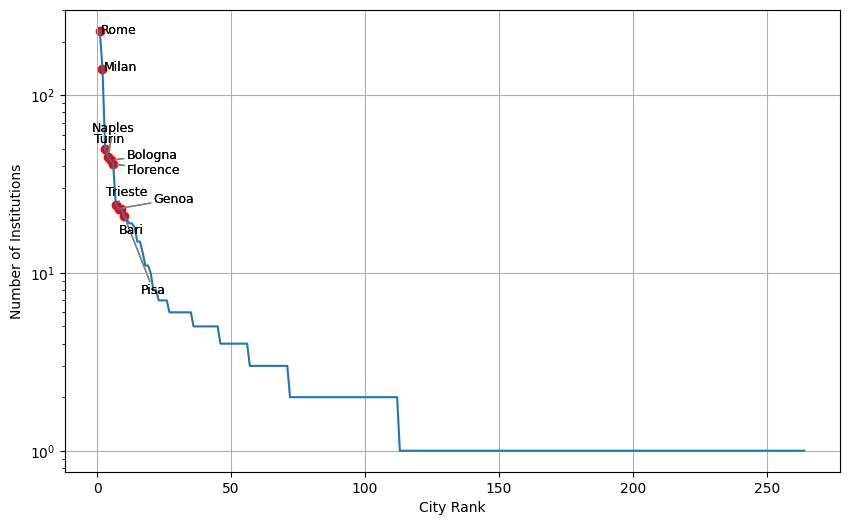

In [36]:
import matplotlib.pyplot as plt

top_n = 10
vc = df['city'].value_counts()

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(vc)+1), vc.values)

# Evidenzia solo le top N città
top = vc.head(top_n)
plt.scatter(range(1, top_n+1), top.values, color='red')

from adjustText import adjust_text

texts = []
for i, txt in enumerate(top.index):
    texts.append(plt.text(i+1, top.values[i], txt, fontsize=9))
adjust_text(texts, arrowprops=dict(arrowstyle='->', color='gray'))

texts = []
for i, txt in enumerate(top.index):
    texts.append(plt.text(i+1, top.values[i], txt, fontsize=9))
adjust_text(texts, arrowprops=dict(arrowstyle='->', color='gray'))

plt.yscale('log')
plt.xlabel("City Rank")
plt.ylabel("Number of Institutions")
plt.grid(True)
plt.show()

##### is_super_system

In [37]:
# Non c'è nemmeno una istituzione che sia un super_system, quindi dato che la variabile non ha variabilità non aggiunge alcune informazione è può essere droppata
df['is_super_system'].value_counts()
df = df.drop('is_super_system', axis = 1)

##### Type

In [38]:
# Anche questo piuttosto sbilanciato
types = df['type'].value_counts()

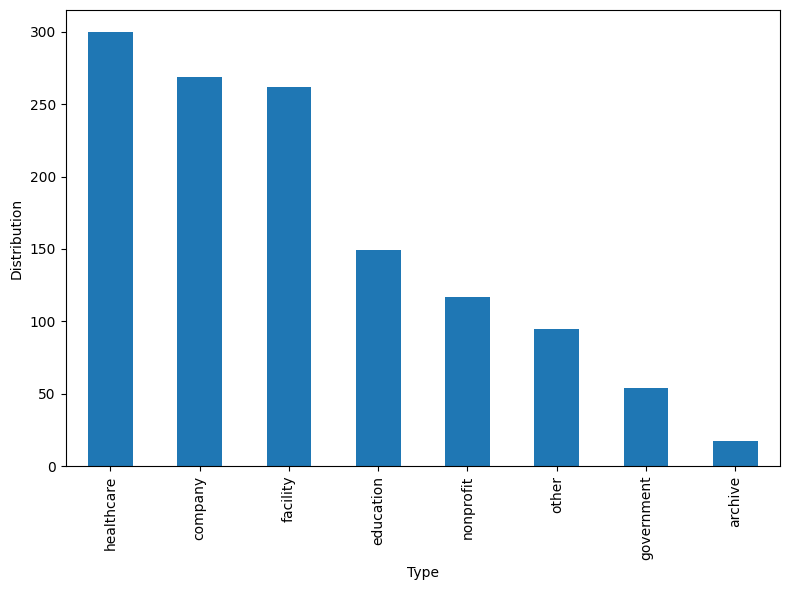

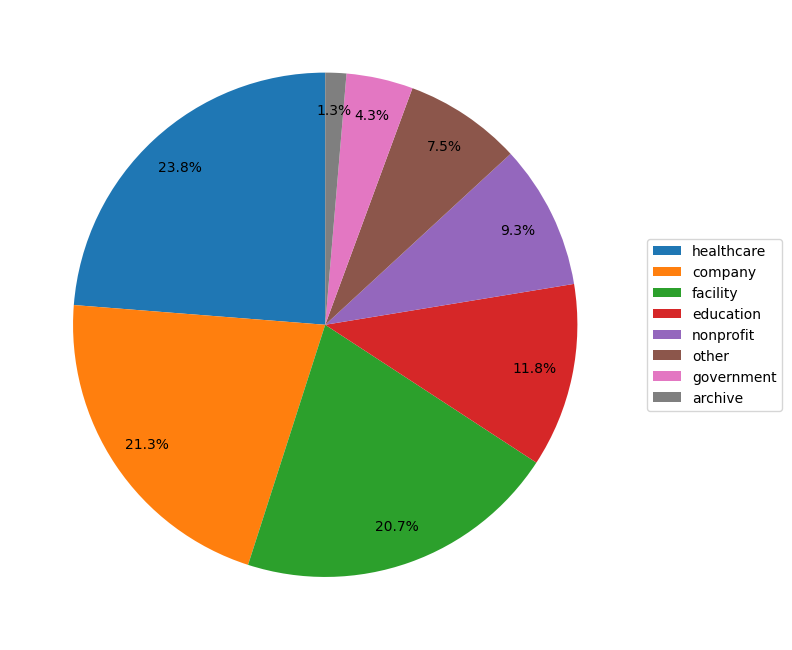

In [39]:
plt.figure(figsize=(8,6))
types.plot(kind='bar')
plt.xlabel('Type')
plt.ylabel('Distribution')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


# Grafico 2: pie chart
plt.figure(figsize=(8,8))
ax = types.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    labels=None,      # Nascondiamo le etichette sulle fette
    pctdistance=0.85
)
plt.legend(types.index, loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))
plt.ylabel('') # Rimuove l'etichetta dell'asse Y automatica di pandas
plt.tight_layout()
plt.show()

#### Altre analisi bivariate

In [40]:
import ast

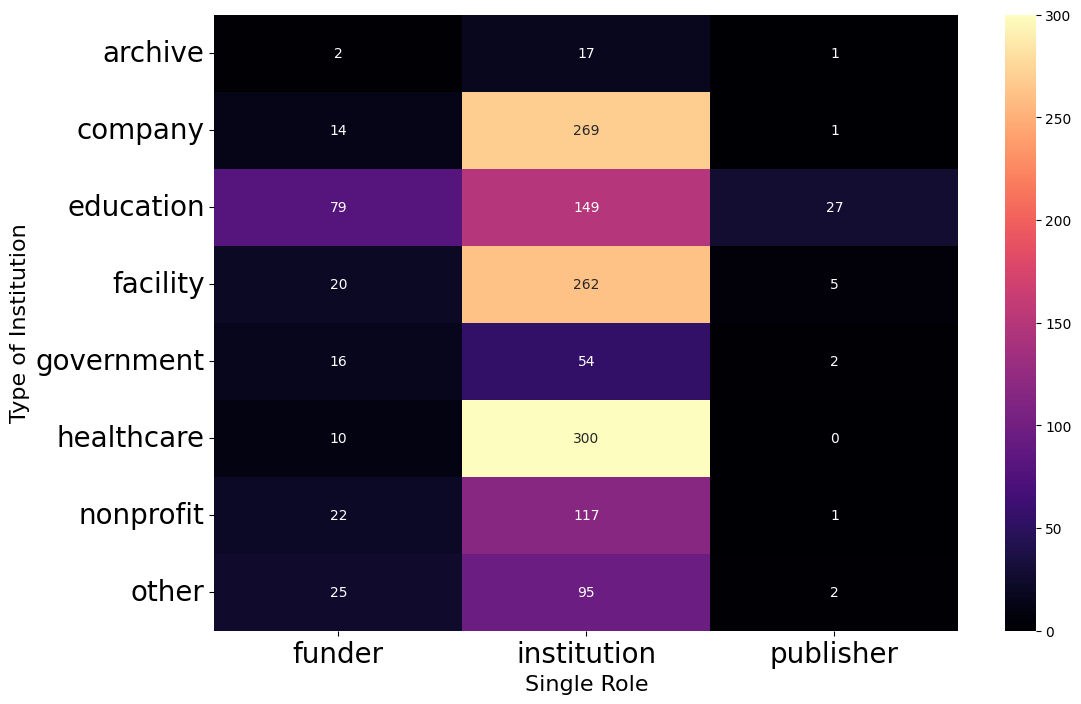

In [41]:
def clean_roles(role_entry):
    # Se è già una lista, la restituiamo
    if isinstance(role_entry, list):
        return role_entry
    # Se è una stringa che sembra una lista (es. "['funder']"), la convertiamo
    if isinstance(role_entry, str) and role_entry.startswith('['):
        try:
            return ast.literal_eval(role_entry)
        except:
            return [role_entry.strip("[]' ")]
    # Se è una stringa separata da virgole
    if isinstance(role_entry, str):
        return [r.strip() for r in role_entry.split(',')]
    return []

# 1. Pulizia profonda
df['roles_cleaned'] = df['roles'].apply(clean_roles)

# 2. Esplosione (trasformiamo ogni lista in righe singole)
df_exploded = df.explode('roles_cleaned')

# 3. Creazione della tabella di contingenza pulita
ct_clean = pd.crosstab(df_exploded['type'], df_exploded['roles_cleaned'])

# 4. Visualizzazione
plt.figure(figsize=(12, 8))
sns.heatmap(ct_clean, annot=True, fmt='d', cmap='magma')
plt.xlabel('Single Role', fontsize = 16)
plt.ylabel('Type of Institution', fontsize = 16)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.show()

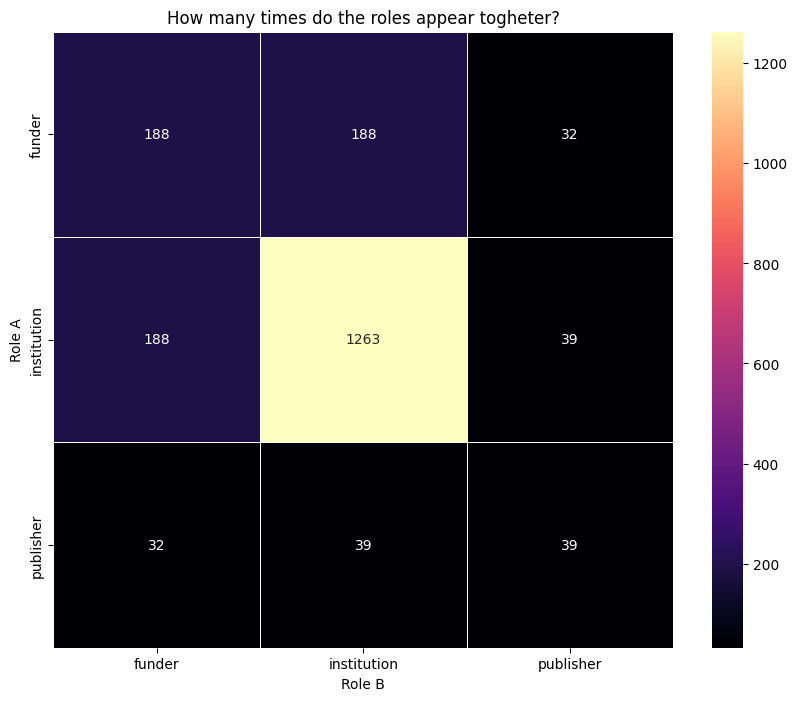

In [42]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Assicuriamoci di avere i dummy puliti (0 e 1 per ogni ruolo)
# roles_dummies è il dataframe creato nel passaggio precedente
# Se non lo hai sottomano, usa: 
roles_dummies = df['roles_cleaned'].apply(lambda x: '|'.join(x)).str.get_dummies(sep='|')

# 2. Calcolo della Co-occorrenza (Prodotto Scalare della matrice trasposta)
# Questo conta quante volte i ruoli appaiono insieme nelle stesse righe
cooccurrence_matrix = roles_dummies.T.dot(roles_dummies)

# 3. Visualizzazione con Palette Magma
plt.figure(figsize=(10, 8))

sns.heatmap(cooccurrence_matrix, 
            annot=True,    # Mostra i numeri (conteggi reali)
            fmt="d",       # Formato intero (decimal)
            cmap='magma',  # La palette scura/gialla
            linewidths=.5)

plt.title('How many times do the roles appear togheter?')
plt.xlabel('Role B')
plt.ylabel('Role A')
plt.show()

/var/folders/32/wr6jfczj32q0c3fcn7fkrtvr0000gn/T/ipykernel_1380/319943608.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=promiscuity_by_type, x='num_roles', y='type', palette='magma')


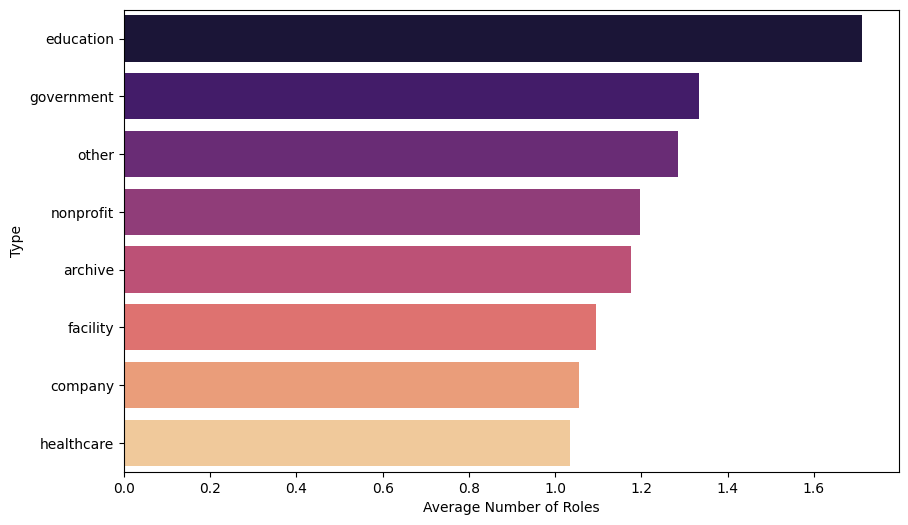

In [43]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Assumiamo di aver già pulito i ruoli in una lista 'roles_list'
# Calcoliamo il numero di ruoli per ogni riga
df['num_roles'] = df['roles_cleaned'].apply(len)

# Media della promiscuità per Tipologia
promiscuity_by_type = df.groupby('type')['num_roles'].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(data=promiscuity_by_type, x='num_roles', y='type', palette='magma')
plt.xlabel('Average Number of Roles')
plt.ylabel('Type')
plt.show()

##### i10_index

<function matplotlib.pyplot.show(close=None, block=None)>

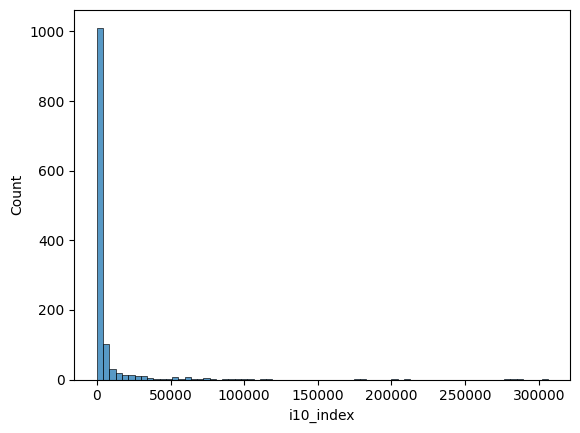

In [44]:
# La variabile è fortemente skewed, dunque ci applichiamo feature transformation con trasformazione logaritmica (la standardizzazione sarà fatta sull'intero dataset più tardi)
sns.histplot(df['i10_index'])
plt.show

In [45]:
# Trasformazione
df['i10_index'] = np.log1p(df['i10_index'])

<function matplotlib.pyplot.show(close=None, block=None)>

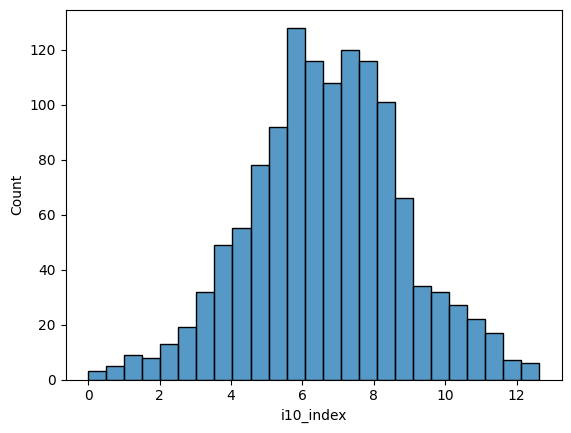

In [46]:
sns.histplot(df['i10_index'])
plt.show

##### Roles

In [47]:
# Mi sembra strano che ci siano solo due roles e soprattutto che non ci siano sovrapposizioni, quindi controlliamo nel dizionario og
import ast

df['roles'] = df['roles'].apply(ast.literal_eval)
df['roles'].value_counts()

roles
[institution]                       1068
[funder, institution]                156
[funder, institution, publisher]      32
[institution, publisher]               7
Name: count, dtype: int64

In [48]:
# Controlliamo quante istituzioni hanno più di un ruolo
print(f'Percentuale di istituzioni che hanno più di un ruolo: {(((df['roles'].map(len) >= 2).sum())/len(df))*100}%')

Percentuale di istituzioni che hanno più di un ruolo: 15.439429928741092%


In [49]:
'''with open('enriched_institutions_final.json', 'r') as outfile:
    dizionario = json.load(outfile)

ruoli = []

for informazioni in dizionario.values():
    for r in informazioni.get('roles', []):
        if 'role' in r:
            ruoli.append(r['role'])

# Infatti, alcuni ruoli si sono persi nella creazione nel dizionario. probabilmente perchè non ho gestito il caso in cui ce ne fosse più di uno
print(set(ruoli))'''

"with open('enriched_institutions_final.json', 'r') as outfile:\n    dizionario = json.load(outfile)\n\nruoli = []\n\nfor informazioni in dizionario.values():\n    for r in informazioni.get('roles', []):\n        if 'role' in r:\n            ruoli.append(r['role'])\n\n# Infatti, alcuni ruoli si sono persi nella creazione nel dizionario. probabilmente perchè non ho gestito il caso in cui ce ne fosse più di uno\nprint(set(ruoli))"

In [50]:
roles = df['roles'].value_counts()
roles.index = [str(x).replace('[', '').replace(']', '').replace("'", "").capitalize() for x in roles.index]

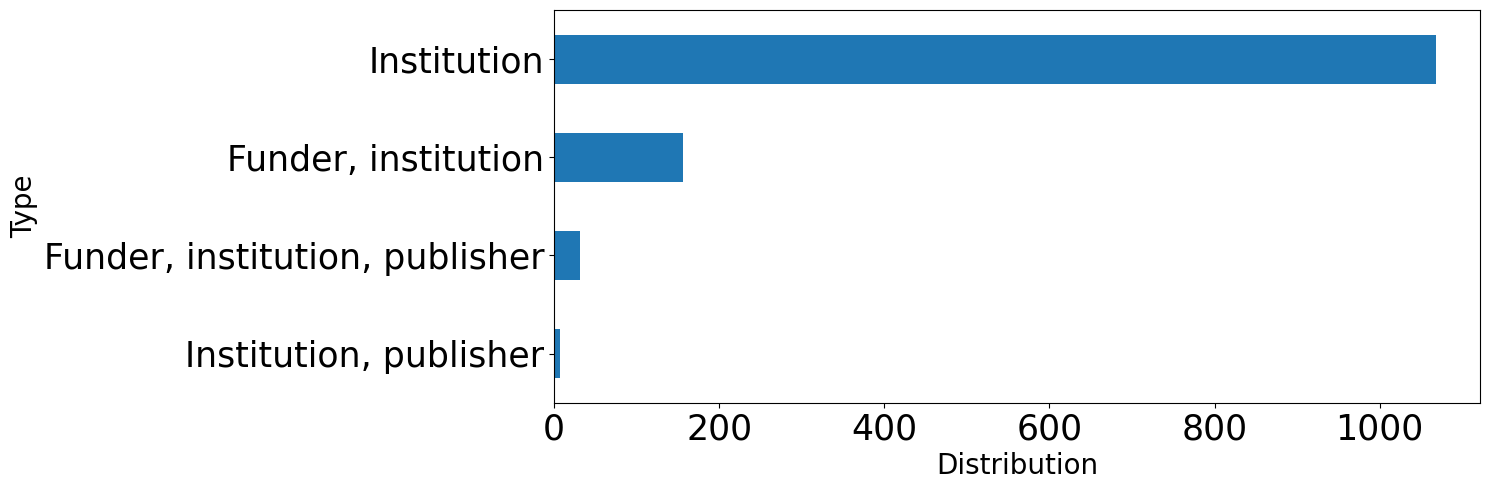

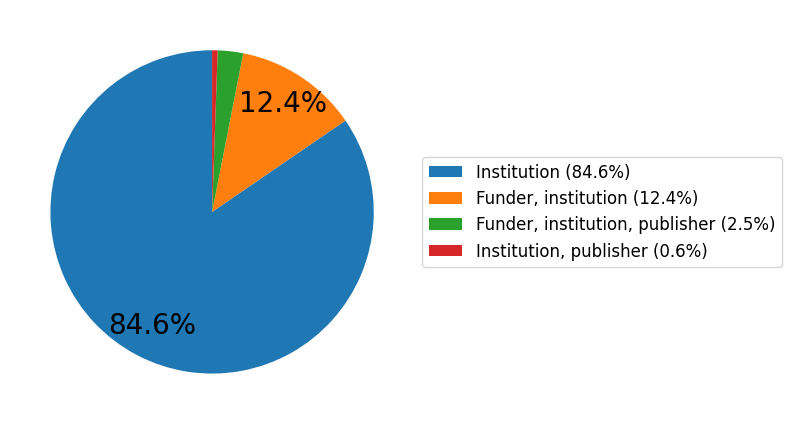

In [51]:
plt.figure(figsize=(15, 5))
roles.plot(kind='barh') # barh = bar horizontal

plt.xlabel('Distribution', fontsize=20)
plt.ylabel('Type', fontsize=20)

plt.gca().tick_params(axis='both', labelsize=25)

plt.gca().invert_yaxis()  # Per avere il valore più alto in cima
plt.tight_layout()


plt.figure(figsize=(8,8))

percentages = roles / roles.sum() * 100

ax = roles.plot(
    kind='pie',
    autopct=lambda pct: f'{pct:.1f}%' if pct > 5 else '',
    startangle=90,
    labels=None,
    pctdistance=0.8,
    textprops={'fontsize': 20}
)

labels = [
    f"{name} ({pct:.1f}%)"
    for name, pct in zip(roles.index, percentages)
]

plt.legend(
    labels,
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1),
    fontsize=12
)

plt.ylabel('')
plt.tight_layout()
plt.show()

##### 2yr_mean_citedness

<function matplotlib.pyplot.show(close=None, block=None)>

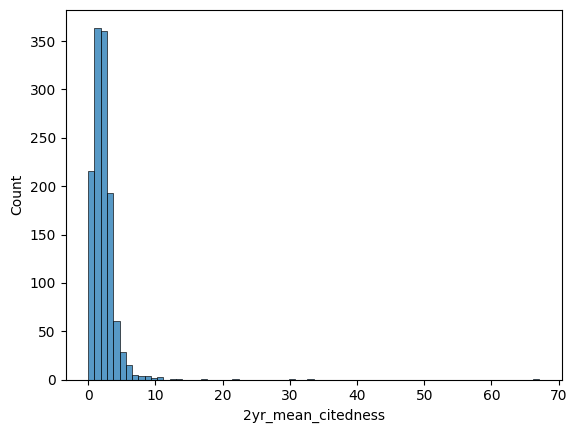

In [52]:
# La variabile è fortemente skewed, dunque ci applichiamo feature transformation con trasformazione logaritmica (la standardizzazione sarà fatta sull'intero dataset più tardi)
sns.histplot(df['2yr_mean_citedness'])
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

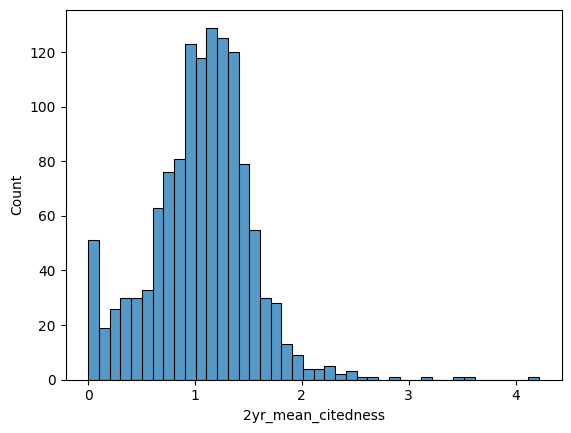

In [53]:
# Un po' meglio
df['2yr_mean_citedness'] = np.log1p(df['2yr_mean_citedness'])
sns.histplot(df['2yr_mean_citedness'])
plt.show

##### h_index

<Axes: xlabel='h_index', ylabel='Count'>

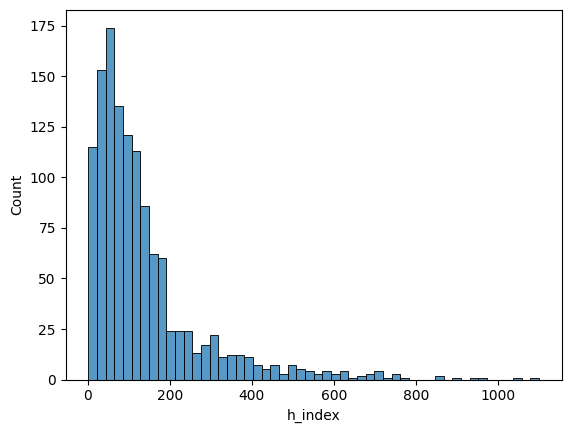

In [54]:
sns.histplot(df['h_index'])

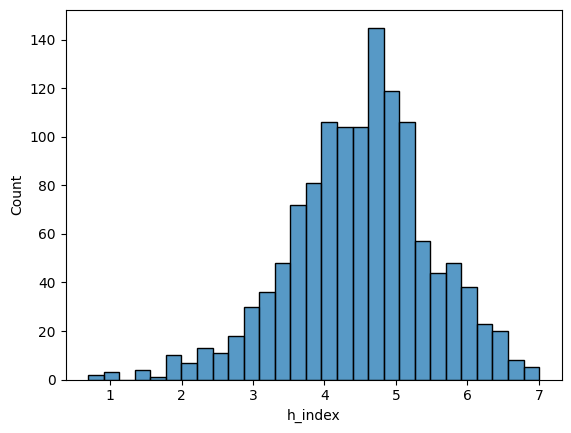

In [55]:
df['h_index'] = np.log1p(df['h_index'])
sns.histplot(df['h_index'])
plt.show()

### Devono essere rimossi h_index, i10_index e 2yr mean citedness

In [56]:
indices_to_remove = ['h_index', 'i10_index', '2yr_mean_citedness']
df = df.drop(indices_to_remove, axis=1)

#### Df dopo primi controlli

In [57]:
df

,nome_istituzione,city,regione,macroarea,type,works_count_2024,cited_by_count_2024,works_count_2023,cited_by_count_2023,works_count_2022,cited_by_count_2022,works_count_2021,cited_by_count_2021,works_count_2020,cited_by_count_2020,works_count_2019,cited_by_count_2019,roles,tot_dipendenti_per_anno_2019,studiosi_usciti_2019,studiosi_entrati_2019,tot_dipendenti_per_anno_2020,studiosi_usciti_2020,studiosi_entrati_2020,tot_dipendenti_per_anno_2021,studiosi_usciti_2021,studiosi_entrati_2021,tot_dipendenti_per_anno_2022,studiosi_usciti_2022,studiosi_entrati_2022,tot_dipendenti_per_anno_2023,studiosi_usciti_2023,studiosi_entrati_2023,tot_dipendenti_per_anno_2024,studiosi_usciti_2024,studiosi_entrati_2024,2020_Health Sciences,2020_Life Sciences,2020_Social Sciences,2020_Physical Sciences,2021_Health Sciences,2021_Life Sciences,2021_Social Sciences,2021_Physical Sciences,2022_Health Sciences,2022_Life Sciences,2022_Social Sciences,2022_Physical Sciences,2023_Health Sciences,2023_Life Sciences,2023_Social Sciences,2023_Physical Sciences,2024_Health Sciences,2024_Life Sciences,2024_Social Sciences,2024_Physical Sciences,roles_cleaned,num_roles
0,Institute of Neurological Sciences,Mangone,Calabria,Sud,facility,108.0,491.0,117.0,960.0,94.0,2851.0,136.0,2447.0,152.0,6189.0,148.0,9442.0,[institution],38.0,17.0,0.0,50.0,35.0,29.0,28.0,20.0,13.0,22.0,12.0,14.0,24.0,11.0,14.0,20.0,10.0,7.0,74.81,22.22,1.48,1.48,73.04,21.74,4.35,0.87,70.37,19.75,8.64,1.23,63.27,29.59,4.08,3.06,65.71,23.81,5.71,4.76,[institution],1
1,University of Siena,Siena,Tuscany,Centro,education,3182.0,13814.0,3034.0,21889.0,2844.0,40025.0,2662.0,53416.0,2719.0,75996.0,2367.0,62857.0,"[funder, institution]",415.0,73.0,0.0,394.0,63.0,52.0,400.0,77.0,69.0,398.0,102.0,75.0,438.0,151.0,142.0,349.0,93.0,62.0,45.11,17.44,14.16,23.30,43.66,17.15,16.17,23.02,44.97,17.19,13.95,23.89,42.75,16.65,15.60,25.01,45.32,15.95,15.75,22.97,"[funder, institution]",2
2,IRCCS Ospedale San Raffaele,Milan,Lombardy,Nord,healthcare,1625.0,8190.0,1629.0,16301.0,1426.0,34961.0,1270.0,38226.0,1163.0,49243.0,823.0,33937.0,[institution],297.0,140.0,0.0,280.0,90.0,123.0,376.0,130.0,186.0,385.0,141.0,139.0,425.0,210.0,181.0,313.0,126.0,98.0,82.78,13.71,2.00,1.50,79.04,17.56,1.42,1.98,73.76,21.86,2.36,2.03,75.72,19.89,2.48,1.92,72.41,23.45,1.57,2.57,[institution],1
3,Bambino Gesù Children's Hospital,Rome,Lazio,Centro,healthcare,1851.0,8472.0,1627.0,14612.0,1804.0,31688.0,1686.0,39876.0,1542.0,55282.0,1138.0,36549.0,[institution],241.0,34.0,0.0,232.0,28.0,25.0,231.0,28.0,27.0,244.0,59.0,41.0,209.0,32.0,24.0,215.0,46.0,38.0,66.37,28.78,2.15,2.70,65.48,28.03,4.12,2.37,66.84,27.35,3.90,1.92,69.99,25.60,2.28,2.13,69.21,25.67,2.96,2.16,[institution],1
4,University of Florence,Florence,Tuscany,Centro,education,8270.0,32069.0,7698.0,66448.0,7750.0,100752.0,7537.0,131602.0,7306.0,173527.0,6296.0,157989.0,"[funder, institution, publisher]",1125.0,161.0,0.0,1141.0,219.0,177.0,1098.0,189.0,176.0,1083.0,205.0,174.0,1043.0,210.0,165.0,949.0,222.0,116.0,32.44,17.50,15.44,34.62,31.94,17.75,15.81,34.51,32.98,16.92,16.39,33.72,33.15,15.82,16.33,34.70,31.83,14.80,17.52,35.85,"[funder, institution, publisher]",3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1258,Ospedale Pediatrico Giovanni XXIII,Bari,NaN,NaN,healthcare,158.0,580.0,167.0,1308.0,182.0,1749.0,152.0,2241.0,145.0,4627.0,71.0,1421.0,[institution],17.0,9.0,0.0,21.0,10.0,13.0,24.0,10.0,13.0,18.0,1.0,4.0,29.0,13.0,12.0,26.0,16.0,10.0,75.86,18.97,2.59,2.59,80.33,13.93,3.28,2.46,74.36,21.79,2.56,1.28,77.54,19.57,1.45,1.45,77.54,16.67,2.90,2.90,[institution],1
1259,Ospedale San Bortolo,Vicenza,NaN,NaN,healthcare,312.0,1537.0,328.0,3031.0,312.0,2998.0,280.0,4931.0,280.0,7011.0,255.0,12609.0,[institution],32.0,4.0,0.0,30.0,4.0,2.0,32.0,6.0,6.0,33.0,12.0,7.0,27.0,7.0,6.0,31.0,15.0,11.0,85.

## Missing values

In [58]:
per_missing = df.isnull().sum() * 100/len(df)
print(per_missing)

nome_istituzione                 0.000000
city                             0.000000
regione                          0.870942
macroarea                        0.870942
type                             0.000000
works_count_2024                 2.929533
cited_by_count_2024              2.929533
works_count_2023                 2.454473
cited_by_count_2023              2.454473
works_count_2022                 2.692003
cited_by_count_2022              2.692003
works_count_2021                 2.216944
cited_by_count_2021              2.216944
works_count_2020                 2.771180
cited_by_count_2020              2.771180
works_count_2019                 3.008709
cited_by_count_2019              3.008709
roles                            0.000000
tot_dipendenti_per_anno_2019    14.568488
studiosi_usciti_2019            14.568488
studiosi_entrati_2019           14.568488
tot_dipendenti_per_anno_2020    13.855899
studiosi_usciti_2020            13.855899
studiosi_entrati_2020           13

#### Missing values: Regione

In [59]:
df['regione'].isna().value_counts()

regione
False    1252
True       11
Name: count, dtype: int64

Per qualche motivo a me sconosciuto tre città non sono state riconosciute in tre entrate. Torino ci sta perché di solito appare come Turin, Bologna e Caserta non ne ho idea. Comunque dato che sono solo tre me le gestisco.-> si sono leggermente moltiplicati dopo alcuni maneggi ma sono comunque poche.

In [60]:
df[df['regione'].isna()]

,nome_istituzione,city,regione,macroarea,type,works_count_2024,cited_by_count_2024,works_count_2023,cited_by_count_2023,works_count_2022,cited_by_count_2022,works_count_2021,cited_by_count_2021,works_count_2020,cited_by_count_2020,works_count_2019,cited_by_count_2019,roles,tot_dipendenti_per_anno_2019,studiosi_usciti_2019,studiosi_entrati_2019,tot_dipendenti_per_anno_2020,studiosi_usciti_2020,studiosi_entrati_2020,tot_dipendenti_per_anno_2021,studiosi_usciti_2021,studiosi_entrati_2021,tot_dipendenti_per_anno_2022,studiosi_usciti_2022,studiosi_entrati_2022,tot_dipendenti_per_anno_2023,studiosi_usciti_2023,studiosi_entrati_2023,tot_dipendenti_per_anno_2024,studiosi_usciti_2024,studiosi_entrati_2024,2020_Health Sciences,2020_Life Sciences,2020_Social Sciences,2020_Physical Sciences,2021_Health Sciences,2021_Life Sciences,2021_Social Sciences,2021_Physical Sciences,2022_Health Sciences,2022_Life Sciences,2022_Social Sciences,2022_Physical Sciences,2023_Health Sciences,2023_Life Sciences,2023_Social Sciences,2023_Physical Sciences,2024_Health Sciences,2024_Life Sciences,2024_Social Sciences,2024_Physical Sciences,roles_cleaned,num_roles
50,Laboratori Guglielmo Marconi (Italy),Bologna,NaN,NaN,company,157.0,666.0,170.0,1511.0,189.0,2582.0,164.0,3046.0,157.0,3174.0,148.0,3120.0,[institution],41.0,13.0,0.0,40.0,12.0,12.0,47.0,17.0,19.0,40.0,19.0,10.0,38.0,16.0,17.0,36.0,10.0,14.0,22.82,8.05,4.03,65.10,14.67,10.00,6.00,69.33,23.86,8.52,9.66,57.95,28.83,16.56,6.13,48.47,22.97,16.89,4.05,56.08,[institution],1
263,"University of Campania ""Luigi Vanvitelli""",Caserta,NaN,NaN,education,3934.0,19381.0,3734.0,39617.0,3729.0,49710.0,3673.0,75021.0,3309.0,103426.0,2599.0,72369.0,"[funder, institution]",516.0,85.0,0.0,505.0,91.0,74.0,531.0,104.0,117.0,514.0,115.0,87.0,489.0,92.0,90.0,476.0,130.0,79.0,52.05,15.30,10.78,21.87,53.48,15.62,10.27,20.63,52.35,16.65,11.00,19.99,51.26,15.91,9.27,23.56,51.21,15.75,9.61,23.43,"[funder, institution]",2
922,Intesa Sanpaolo (Italy),Turin,NaN,NaN,company,11.0,5.0,10.0,33.0,13.0,237.0,21.0,46.0,13.0,18.0,6.0,4.0,[institution],NaN,NaN,NaN,1.0,0.0,0.0,NaN,NaN,NaN,1.0,0.0,0.0,NaN,NaN,NaN,1.0,0.0,0.0,NaN,NaN,84.62,15.38,5.26,NaN,89.47,5.26,NaN,NaN,81.82,18.18,12.50,12.50,75.00,NaN,9.09,NaN,45.45,45.45,[institution],1
1255,Agostino Gemelli University Polyclinic,Rome,NaN,NaN,healthcare,4010.0,20773.0,3988.0,43521.0,3709.0,61702.0,3484.0,90248.0,3257.0,129833.0,2049.0,70321.0,[institution],509.0,113.0,0.0,535.0,116.0,139.0,503.0,90.0,84.0,568.0,143.0,155.0,513.0,108.0,88.0,507.0,143.0,102.0,78.69,14.85,3.78,2.68,79.98,14.78,2.83,2.41,80.98,13.29,3.19,2.53,81.22,14.21,2.17,2.40,80.34,14.21,2.18,3.28,[institution],1
1256,Istituto Nazionale di Geofisica e Vulcanologia,Rome,NaN,NaN,facility,1601.0,3413.0,1752.0,5809.0,1382.0,11124.0,1280.0,14434.0,1177.0,20979.0,786.0,17233.0,"[funder, institution, publisher]",261.0,20.0,0.0,262.0,14.0,21.0,268.0,13.0,20.0,274.0,17.0,19.0,270.0,29.0,13.0,264.0,63.0,23.0,1.51,2.22,5.15,91.12,0.99,2.35,4.34,92.32,1.95,1.78,3.99,92.28,1.36,1.92,4.24,92.48,2.63,1.89,4.93,90.56,"[funder, institution, publisher]",3
1257,Cereal Research Centre,Foggia,NaN,NaN,facility,323.0,1424.0,372.0,2907.0,326.0,4800.0,329.0,6916.0,325.0,11865.0,284.0,11331.0,[institution],81.0,17.0,0.0,82.0,18.0,18.0,80.0,25.0,16.0,72.0,24.0,17.0,69.0,16.0,21.0,66.0,26.0,13.0,15.60,61.35,2.13,20.92,12.36,68.16,2.62,16.85,14.24,59.72,3.82,22.22,13.48,61.13,3.45,21.94,8.90,64.77,2.49,23.84,[institution],1
1258,Ospedale Pediatrico Giovanni XXIII,Bari,NaN,NaN,healthcare,158.0,580.0,167.0,1308.0,182.0,1749.0,152.0,2241.0,145.0,4627.0,71.0,1421.0,[institution],17.0,9.0,0.0,21.0,10.0,13.0,24.0,10.0,13.0,18.0,1.0,4.0,29.0,13.0,12.0,26.0,16.0,10.0,75.86,18.97,2.59,2.59,80.33,13.93,3.28,2.46,74.36,21.79,2.56,1.28,77.54,19.57,1.45,1.45,77.54,16.67,2.90,2.90,[institution],1
1259,Ospedale San Bortolo,Vicenza,NaN,NaN,healthcare,312.0,1537.0,328.0,3031.0,312.0,2998.0,280.0,4931.0,280.0,7011.0,255.0,12609.0,[institution],32.0,4.0,0.0,30.0,

In [61]:
df.loc[df.index[1259], ['regione', 'macroarea']] = ['Veneto', 'Nord']

In [62]:
df.loc[df.index[50], ['regione', 'macroarea']] = ['Emilia-Romagna', 'Nord']

In [63]:
df.loc[df.index[263], ['regione', 'macroarea']] = ['Campania', 'Sud']

In [64]:
df.loc[df.index[[922, 1262]], ['regione', 'macroarea']] = ['Piedmont', 'Nord']

In [65]:
df.loc[df.index[[1257, 1258]], ['regione', 'macroarea']] = ['Apulia', 'Sud']

In [66]:
df.loc[df.index[[1260, 1256, 1255]], ['regione', 'macroarea']] = ['Lazio', 'Centro']

In [67]:
df.loc[df.index[1261], ['regione', 'macroarea']] = ['Lombardy', 'Nord']

#### Missing Values: Macroarea
Risolta in regioni.iypnb e nel codice sopra.

In [68]:
df['macroarea'].isna().value_counts()

macroarea
False    1263
Name: count, dtype: int64

In [69]:
df[df['macroarea'].isna()]

,nome_istituzione,city,regione,macroarea,type,works_count_2024,cited_by_count_2024,works_count_2023,cited_by_count_2023,works_count_2022,cited_by_count_2022,works_count_2021,cited_by_count_2021,works_count_2020,cited_by_count_2020,works_count_2019,cited_by_count_2019,roles,tot_dipendenti_per_anno_2019,studiosi_usciti_2019,studiosi_entrati_2019,tot_dipendenti_per_anno_2020,studiosi_usciti_2020,studiosi_entrati_2020,tot_dipendenti_per_anno_2021,studiosi_usciti_2021,studiosi_entrati_2021,tot_dipendenti_per_anno_2022,studiosi_usciti_2022,studiosi_entrati_2022,tot_dipendenti_per_anno_2023,studiosi_usciti_2023,studiosi_entrati_2023,tot_dipendenti_per_anno_2024,studiosi_usciti_2024,studiosi_entrati_2024,2020_Health Sciences,2020_Life Sciences,2020_Social Sciences,2020_Physical Sciences,2021_Health Sciences,2021_Life Sciences,2021_Social Sciences,2021_Physical Sciences,2022_Health Sciences,2022_Life Sciences,2022_Social Sciences,2022_Physical Sciences,2023_Health Sciences,2023_Life Sciences,2023_Social Sciences,2023_Physical Sciences,2024_Health Sciences,2024_Life Sciences,2024_Social Sciences,2024_Physical Sciences,roles_cleaned,num_roles


#### Missing Values: works and citations

In [70]:
print(f'Quantità di valori nan in {df['works_count_2019'].isna().value_counts()}')
print(f'Quantità di valori nan in {df['works_count_2020'].isna().value_counts()}')
print(f'Quantità di valori nan in {df['works_count_2021'].isna().value_counts()}')
print(f'Quantità di valori nan in {df['works_count_2022'].isna().value_counts()}')
print(f'Quantità di valori nan in {df['works_count_2023'].isna().value_counts()}')

Quantità di valori nan in works_count_2019
False    1225
True       38
Name: count, dtype: int64
Quantità di valori nan in works_count_2020
False    1228
True       35
Name: count, dtype: int64
Quantità di valori nan in works_count_2021
False    1235
True       28
Name: count, dtype: int64
Quantità di valori nan in works_count_2022
False    1229
True       34
Name: count, dtype: int64
Quantità di valori nan in works_count_2023
False    1232
True       31
Name: count, dtype: int64


In [71]:
print(f'Quantità di valori nan in {df['cited_by_count_2019'].isna().value_counts()}')
print(f'Quantità di valori nan in {df['cited_by_count_2020'].isna().value_counts()}')
print(f'Quantità di valori nan in {df['cited_by_count_2021'].isna().value_counts()}')
print(f'Quantità di valori nan in {df['cited_by_count_2022'].isna().value_counts()}')
print(f'Quantità di valori nan in {df['cited_by_count_2023'].isna().value_counts()}')

Quantità di valori nan in cited_by_count_2019
False    1225
True       38
Name: count, dtype: int64
Quantità di valori nan in cited_by_count_2020
False    1228
True       35
Name: count, dtype: int64
Quantità di valori nan in cited_by_count_2021
False    1235
True       28
Name: count, dtype: int64
Quantità di valori nan in cited_by_count_2022
False    1229
True       34
Name: count, dtype: int64
Quantità di valori nan in cited_by_count_2023
False    1232
True       31
Name: count, dtype: int64


Per comprendere il modo migliore di riempire i NaN, analiziamo la distribuzione dei valori in base al tipo di istituzione.

In [72]:
works_cols = ['works_count_2024', 'works_count_2023', 'works_count_2022', 'works_count_2021', 'works_count_2020', 'works_count_2019']
cited_cols = ['cited_by_count_2024', 'cited_by_count_2023', 'cited_by_count_2022', 'cited_by_count_2021', 'cited_by_count_2020']

In [73]:
# Lavoriamo su una copia del df dal quale droppiamo i nan per comprendere meglio le distribuzioni delle colonne che ci interessano
df_dispersione = df.dropna().copy()
df_dispersione.shape

(451, 58)

In [74]:
# Coefficiente di variazione
df_dispersione['works_cv'] = df_dispersione[works_cols].std(axis=1) / df_dispersione[works_cols].mean(axis=1)

df_dispersione['cited_cv'] = df_dispersione[cited_cols].std(axis=1) / df_dispersione[cited_cols].mean(axis=1)

# Aggregato per tipo
cv_per_tipo = df_dispersione.groupby('type')[['works_cv', 'cited_cv']].mean()
print(cv_per_tipo)

            works_cv  cited_cv
type                          
archive     0.396951  0.668989
company     0.267374  0.662250
education   0.187923  0.588885
facility    0.186011  0.639834
government  0.291981  0.676064
healthcare  0.212694  0.667592
nonprofit   0.243782  0.711603
other       0.210845  0.665648


L'impressione controllando a vista sia che ci sono outlier che aumentano notevolmente la skewness, dunque proviamo a visualizzarli e poi a rimuoverli.

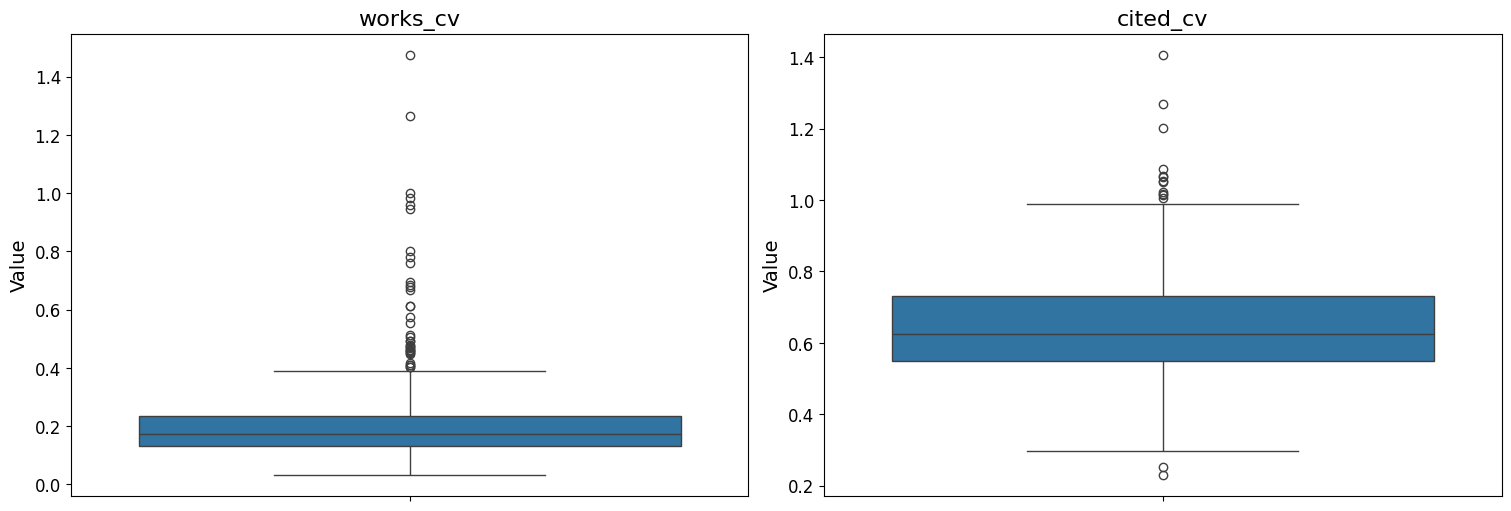

In [75]:
# Visualizzazione con boxplot degli outlier indipendentemente dal tipo
numerical_columns = df_dispersione[['works_cv', 'cited_cv']]
columns = 2
rows = 1

fig, axes = plt.subplots(rows, columns, figsize= (15, 5*rows), constrained_layout = True)
axes = axes.flatten()

for i, col in enumerate(numerical_columns):
    sns.boxplot(df_dispersione[col], ax=axes[i])
    
    axes[i].set_title(col, fontsize=16)        # titolo
    axes[i].set_xlabel('', fontsize=14)        # asse x (vuoto ma controllabile)
    axes[i].set_ylabel('Value', fontsize=14)   # asse y
    
    axes[i].tick_params(axis='both', labelsize=12)  # tick
    
for i in range(len(numerical_columns), len(axes)):
    fig.delaxes(axes[i])
    
plt.show()

In [76]:
def boxplot_by_inst(dataframe):
    for tipo in dataframe['type'].unique():
        colonne = dataframe[dataframe['type'] == tipo][['works_cv', 'cited_cv']]
        columns = 2
        rows = 1

        fig, axes = plt.subplots(rows, columns, figsize=(15, 5*rows), constrained_layout=True)
        axes = axes.flatten()

        for i, col in enumerate(colonne):
            sns.boxplot(colonne[col], ax=axes[i])
            
            axes[i].set_title(f'{tipo}_{col}', fontsize=20)
            axes[i].set_ylabel('Value', fontsize=20)
            axes[i].tick_params(axis='both', labelsize=20)

        for i in range(len(colonne), len(axes)):
            fig.delaxes(axes[i])

        plt.show()

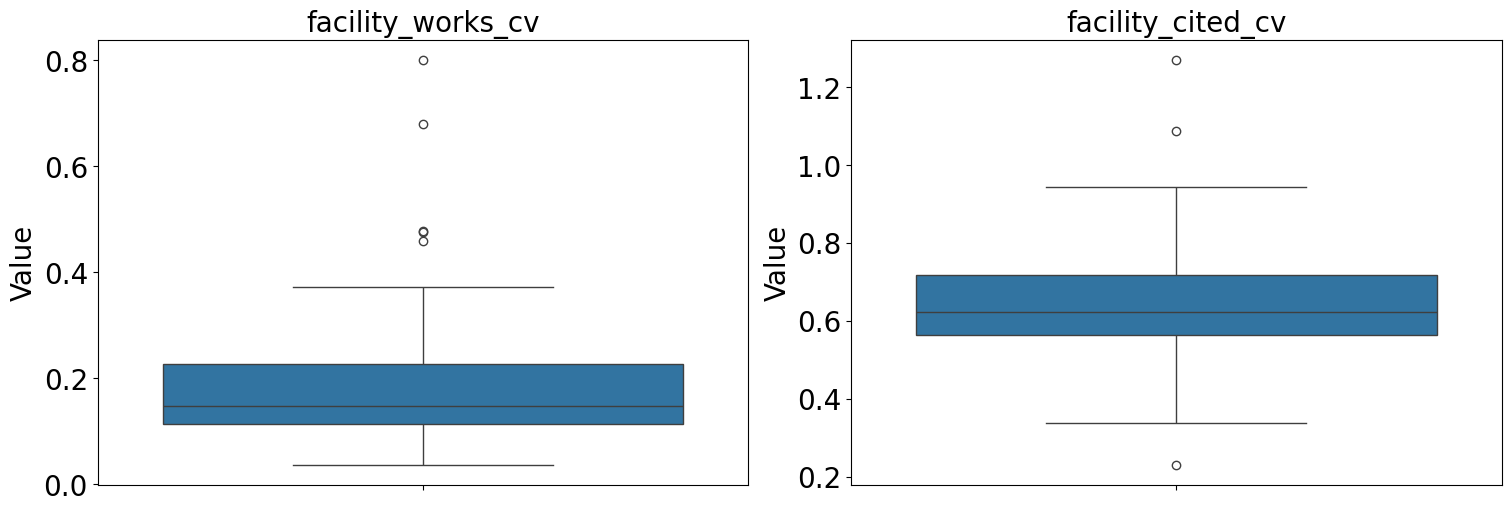

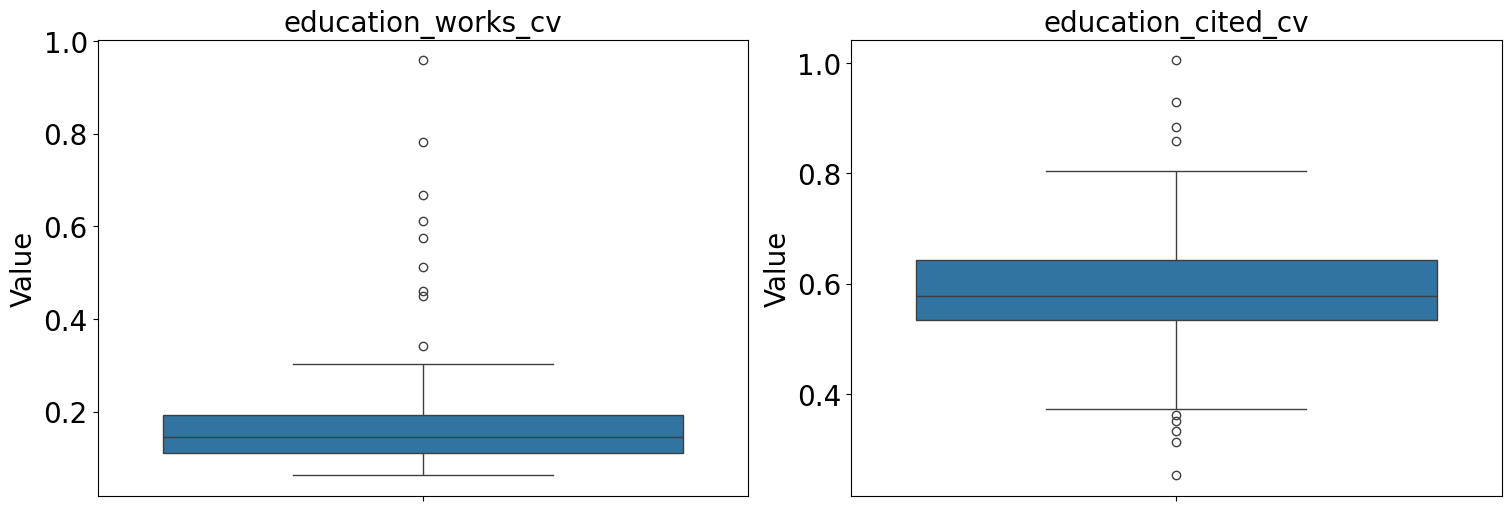

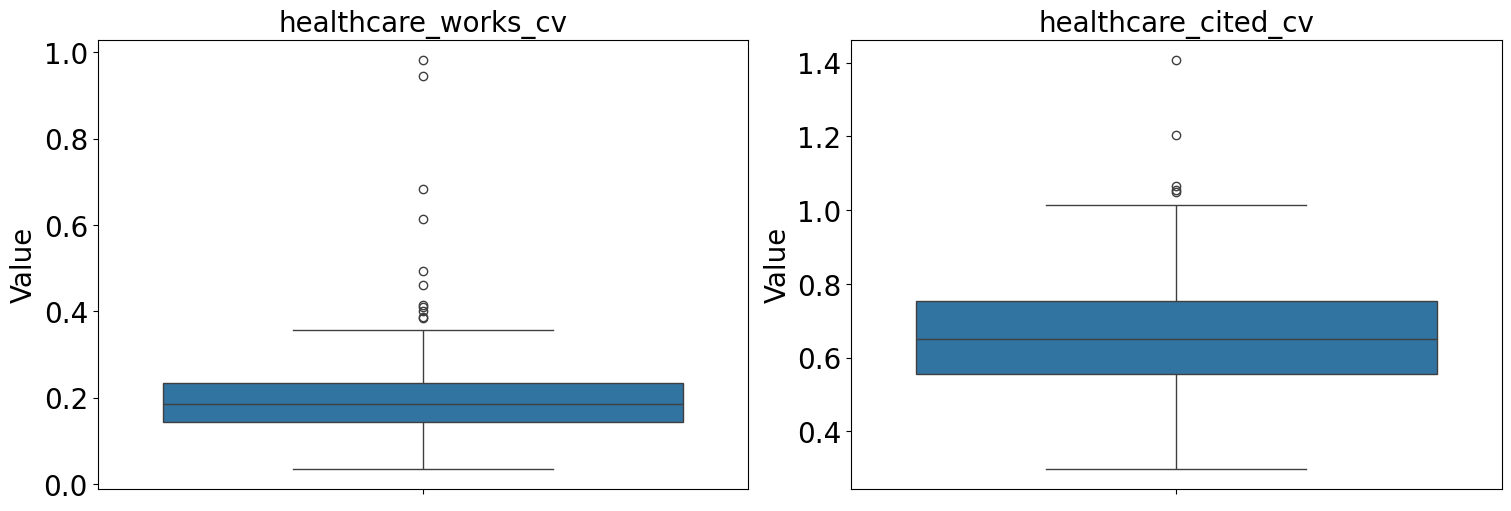

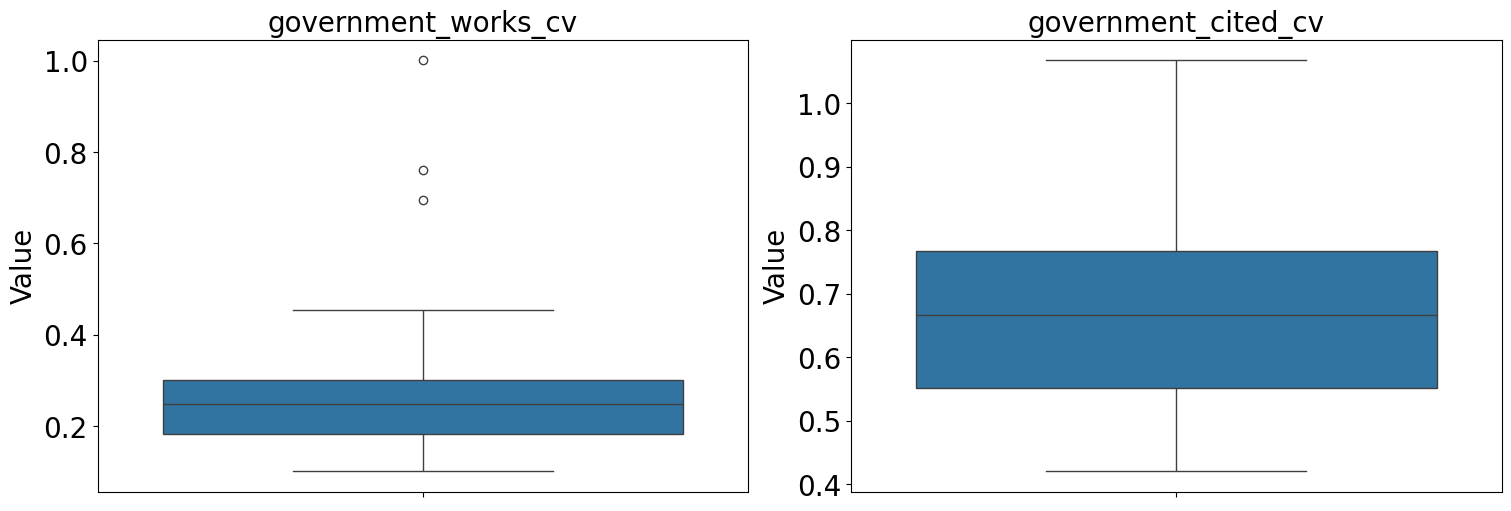

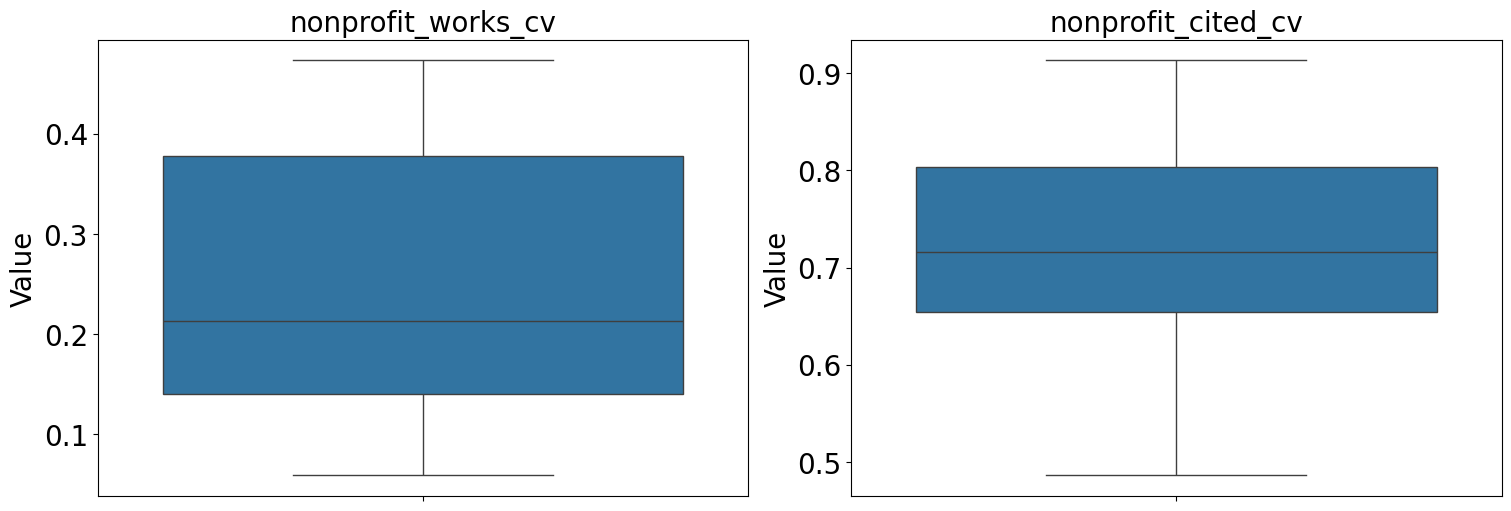

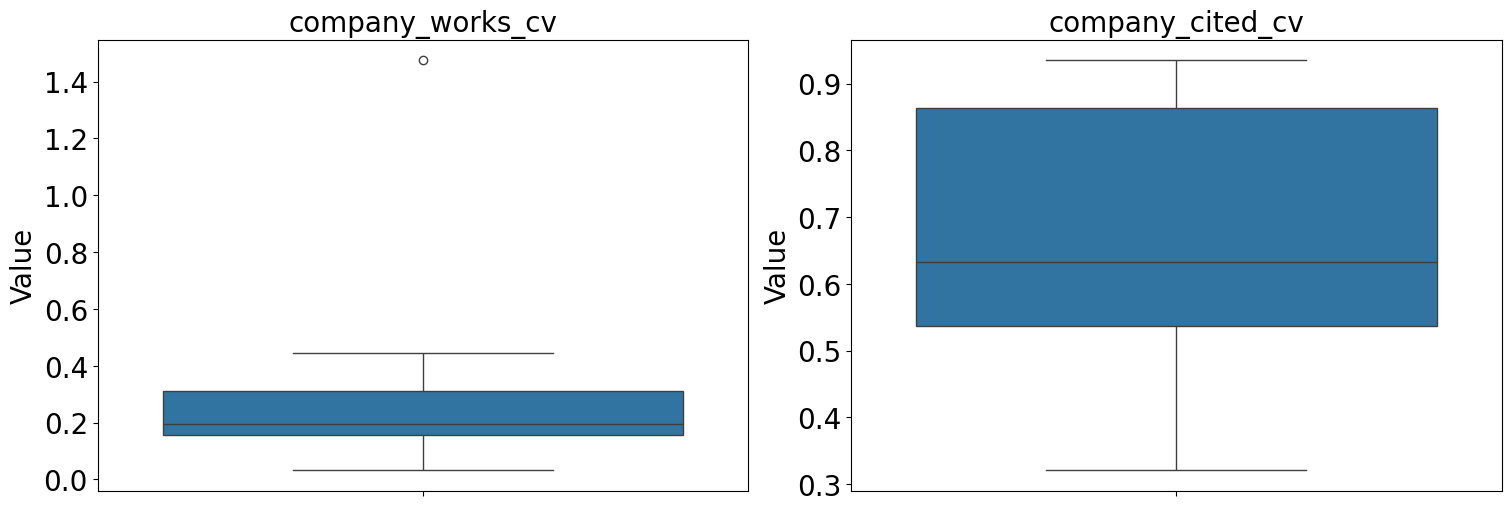

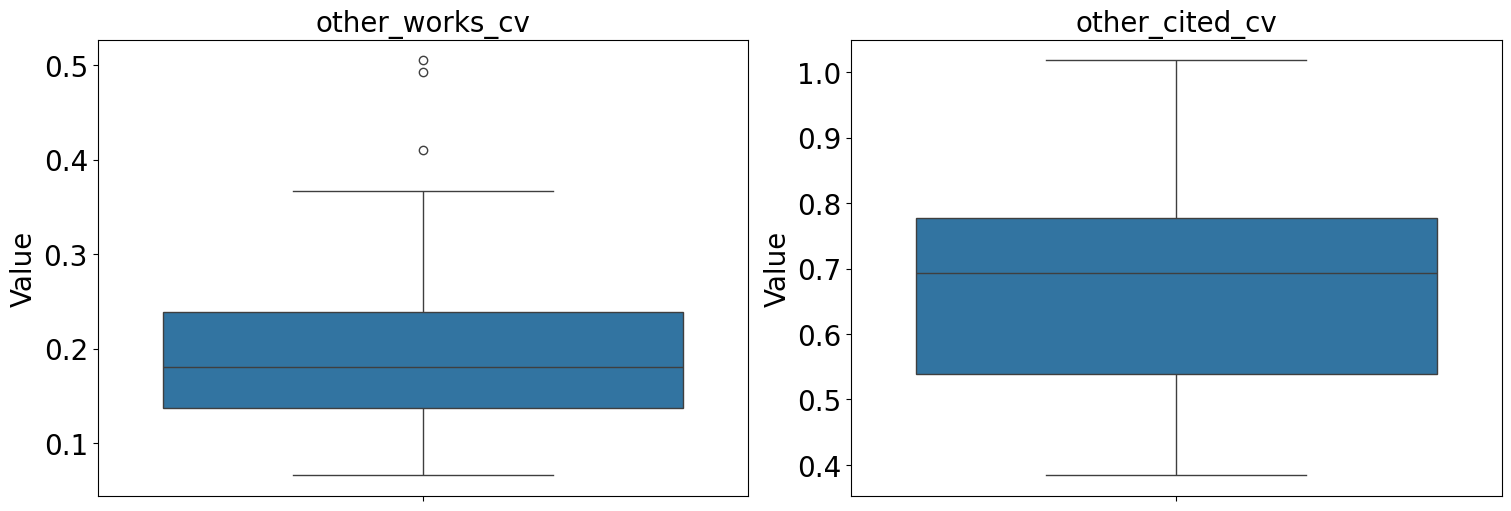

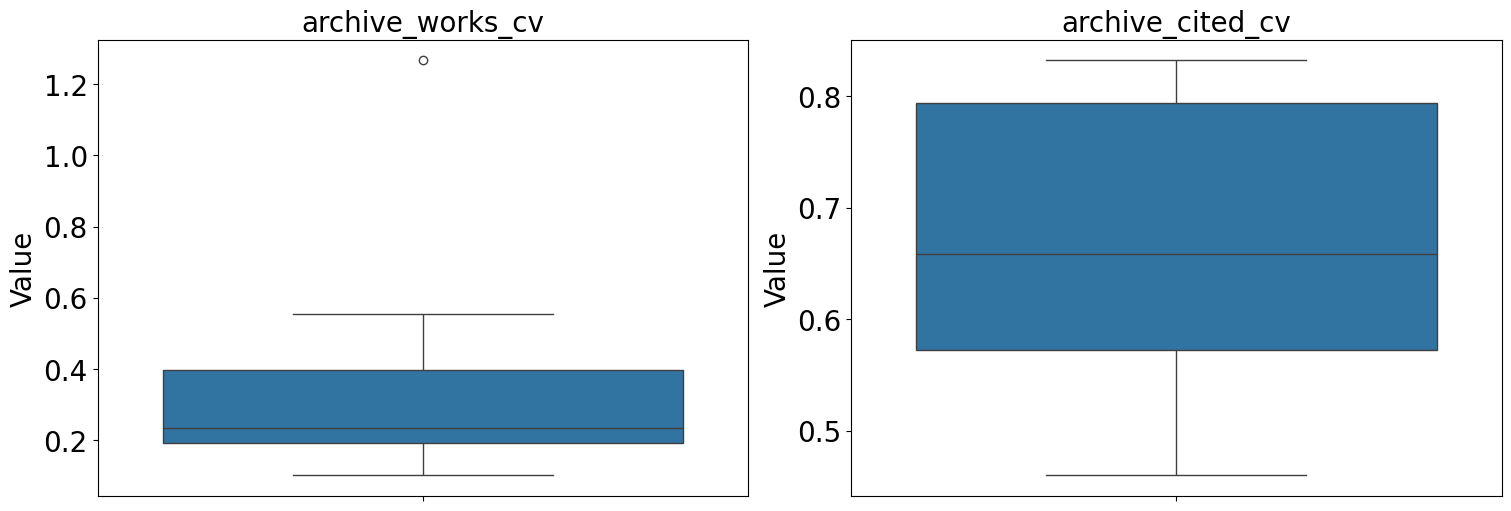

In [77]:
boxplot_by_inst(df_dispersione)

Gli outlier si concentrano maggiormente nei casi di healthcare, education e facility: per queste la media non è un indicatore corretto, useremo dunque la mediana tra gli anni precedenti per riempire i buchi in works_count e cited_by_count.

Eliminiamo tutte le istituzioni che hanno due valori nan di fila per gli anni e/o il 2023  mancanti.

In [78]:
def drop_nan_columns(dataframe):
    df_copy = dataframe.copy()
    column_types = ['works_count', 'cited_by_count']
    years = [2019, 2020, 2021, 2022, 2023, 2024]
    
    for col_type in column_types:
        for year in years[1:-2]:  # [2020, 2021, 2022]
            col = f'{col_type}_{year}'
            prev_col = f'{col_type}_{year - 1}'
            next_col = f'{col_type}_{year + 1}'
            
            mask = (
                df_copy[col].isna() &
                (df_copy[prev_col].isna() | df_copy[next_col].isna())
            )
            df_copy = df_copy.loc[~mask]
        
        # Gestione separata per il 2023 (ultimo anno)
        col_2023 = f'{col_type}_2023'
        mask_2023 = df_copy[col_2023].isna()
        df_copy = df_copy.loc[~mask_2023]
    
    return df_copy

In [79]:
df_copy = drop_nan_columns(df)

In [80]:
per_missing_df_copy = df_copy.isnull().sum() * 100/len(df_copy)
print(per_missing_df_copy)

nome_istituzione                 0.000000
city                             0.000000
regione                          0.000000
macroarea                        0.000000
type                             0.000000
works_count_2024                 1.233553
cited_by_count_2024              1.233553
works_count_2023                 0.000000
cited_by_count_2023              0.000000
works_count_2022                 0.740132
cited_by_count_2022              0.740132
works_count_2021                 0.411184
cited_by_count_2021              0.411184
works_count_2020                 0.411184
cited_by_count_2020              0.411184
works_count_2019                 1.151316
cited_by_count_2019              1.151316
roles                            0.000000
tot_dipendenti_per_anno_2019    12.500000
studiosi_usciti_2019            12.500000
studiosi_entrati_2019           12.500000
tot_dipendenti_per_anno_2020    11.348684
studiosi_usciti_2020            11.348684
studiosi_entrati_2020           11

Riempiamo i buchi in quest'area delle istituzioni con la mediana tra gli anni precedente e successivo

In [81]:
def fill_nan_years(df):
    df_filled = df.copy()
    column_types = ['works_count', 'cited_by_count']
    years = [2019, 2020, 2021, 2022, 2023, 2024]
    
    for col_type in column_types:
        for year in years:
            col_name = f'{col_type}_{year}'
            if col_name not in df_filled.columns:
                continue
            
            else:
                # Riempi con mediana degli anni adiacenti
                prev_col = f'{col_type}_{year - 1}'
                next_col = f'{col_type}_{year + 1}'
                if prev_col in df_filled.columns and next_col in df_filled.columns:
                    median_vals = df_filled[[prev_col, next_col]].median(axis=1)
                    df_filled[col_name] = df_filled[col_name].fillna(median_vals)
    
    return df_filled

# Usa la funzione
df = fill_nan_years(df_copy)

Drop delle colonne relative ai works_count e cited_by_count del 2019 ma anche del 2024 (che non ci serviranno in seguito) che hanno assolto alla loro funzione.

In [82]:
df = df.drop(['works_count_2019', 'cited_by_count_2019', 'works_count_2024', 'cited_by_count_2024'], axis=1)

In [83]:
per_missing_df1 = df.isnull().sum() * 100/len(df)
print(per_missing_df1)

nome_istituzione                 0.000000
city                             0.000000
regione                          0.000000
macroarea                        0.000000
type                             0.000000
works_count_2023                 0.000000
cited_by_count_2023              0.000000
works_count_2022                 0.000000
cited_by_count_2022              0.000000
works_count_2021                 0.000000
cited_by_count_2021              0.000000
works_count_2020                 0.000000
cited_by_count_2020              0.000000
roles                            0.000000
tot_dipendenti_per_anno_2019    12.500000
studiosi_usciti_2019            12.500000
studiosi_entrati_2019           12.500000
tot_dipendenti_per_anno_2020    11.348684
studiosi_usciti_2020            11.348684
studiosi_entrati_2020           11.348684
tot_dipendenti_per_anno_2021    12.335526
studiosi_usciti_2021            12.335526
studiosi_entrati_2021           12.335526
tot_dipendenti_per_anno_2022    12

### Missing values: papers
Assumiamo che i paper mancanti per ogni anno e macroarea siano dovuti alla specializzazione degli istituti e quindi che equivalgano a zero paper prodotti in quell'ambito perchè l'istituzione non si occupa di quello.

In [84]:
colonne_papers = df.filter(regex=r"^\d{4}_").columns.tolist()

In [85]:
# Assumiamo che se hanno valore uguale a zero è perché non sono stati prodotti paper in quell'ambito
df[colonne_papers] = df[colonne_papers].fillna(0).copy()

In [86]:
df.to_csv('df_regression.csv', index=False)

### Missing values: dipendenti e persone uscite-> tot_dipendenti_per_anno, studiosi_usciti, studiosi_entrati
Essendo che i valori mancanti vanno dal 14% al 17%, analizziamo un po' la variabile nell'ottica di provare due diversi metodi di riempimento:
- Misure di tendenza
- Allenare modello di ml

In [87]:
columns_tot_dipendenti = []
columns_entries = []
columns_leaving = []

colonne = df.columns
for i in colonne:
    if 'dipendenti' in i:
        columns_tot_dipendenti.append(i)

    elif 'studiosi_entrati' in i:
        columns_entries.append(i)

    elif 'studiosi_usciti' in i:
        columns_leaving.append(i)

In [88]:
# Vediamo a quali anni appartengono i valori non presenti relativi ai dipendenti
columns_dipendenti = list(set(columns_tot_dipendenti) | set(columns_entries) | set(columns_leaving))
per_missing_df = df[columns_dipendenti].isnull().sum() * 100/len(df)
print(f'Percentuali di valori mancanti nelle colonne relative ai dipendenti {per_missing_df}')
print(f'Somma dei NaN nelle colonne dei dipendenti {df[columns_dipendenti].isnull().sum()}')
# Maggiormente al 2024, che essendo l'anno più recente ha senso, molti dei paper probabilmente non sono stati registrati ancora

Percentuali di valori mancanti nelle colonne relative ai dipendenti studiosi_usciti_2024            14.967105
studiosi_usciti_2019            12.500000
studiosi_usciti_2022            12.500000
tot_dipendenti_per_anno_2023    11.759868
tot_dipendenti_per_anno_2019    12.500000
studiosi_entrati_2020           11.348684
studiosi_entrati_2021           12.335526
studiosi_entrati_2023           11.759868
studiosi_entrati_2022           12.500000
tot_dipendenti_per_anno_2024    14.967105
studiosi_usciti_2023            11.759868
tot_dipendenti_per_anno_2022    12.500000
tot_dipendenti_per_anno_2021    12.335526
studiosi_entrati_2024           14.967105
tot_dipendenti_per_anno_2020    11.348684
studiosi_usciti_2020            11.348684
studiosi_entrati_2019           12.500000
studiosi_usciti_2021            12.335526
dtype: float64
Somma dei NaN nelle colonne dei dipendenti studiosi_usciti_2024            182
studiosi_usciti_2019            152
studiosi_usciti_2022            152
tot_dipend

In [89]:
df_no_nan = df.dropna().copy()
df_no_nan.shape

(905, 54)

##### Boxplot tot_dipendenti

In [90]:
df_no_nan['type'].unique()

array(['facility', 'education', 'healthcare', 'government', 'nonprofit',
       'company', 'other', 'archive'], dtype=object)

In [91]:
# Controlliamo la distribuzione per anno della variabile senza nan
def distrib_peoples_data(dataframe, cols):
    for tipo in dataframe['type'].unique():
        colonne = dataframe[dataframe['type'] == tipo][cols]
        columns = 6
        rows = 1

        fig, axes = plt.subplots(rows, columns, figsize= (15, 5*rows), constrained_layout = True)
        axes = axes.flatten()

        for i, col in enumerate(colonne):
            sns.boxplot(colonne[col], ax = axes[i])
            axes[i].set_title(f'{tipo}_{col}')
            
        for i in range(len(colonne), len(axes)):
            fig.delaxes(axes[i])
            
        plt.show()

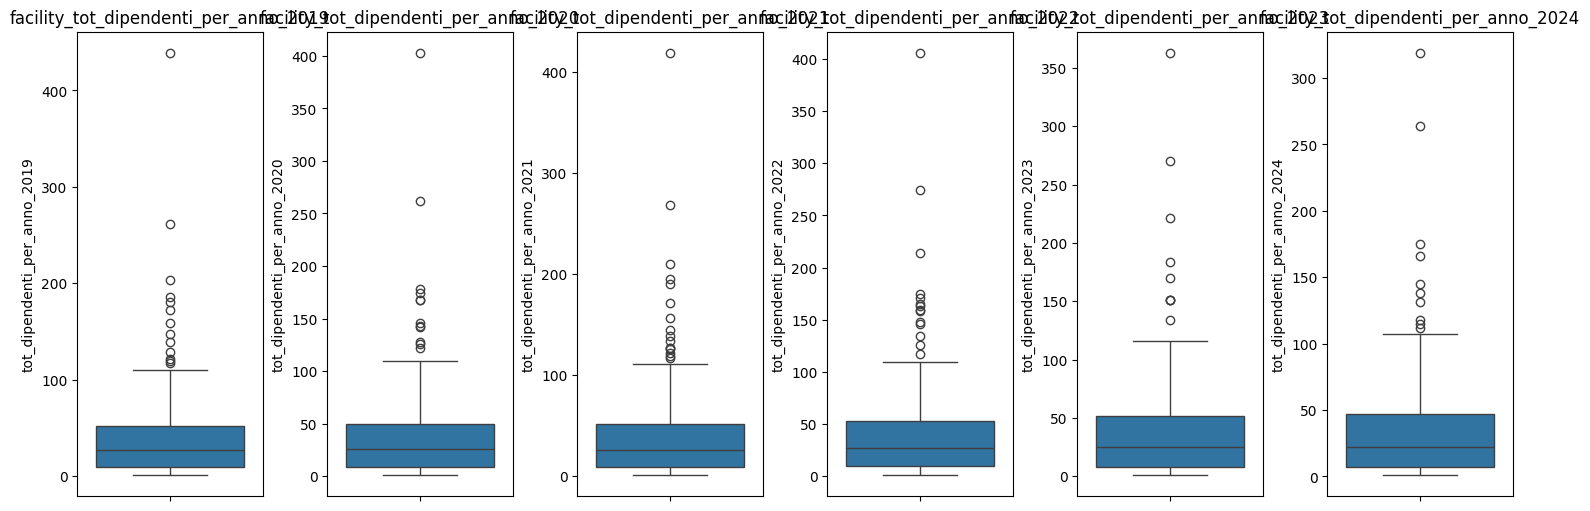

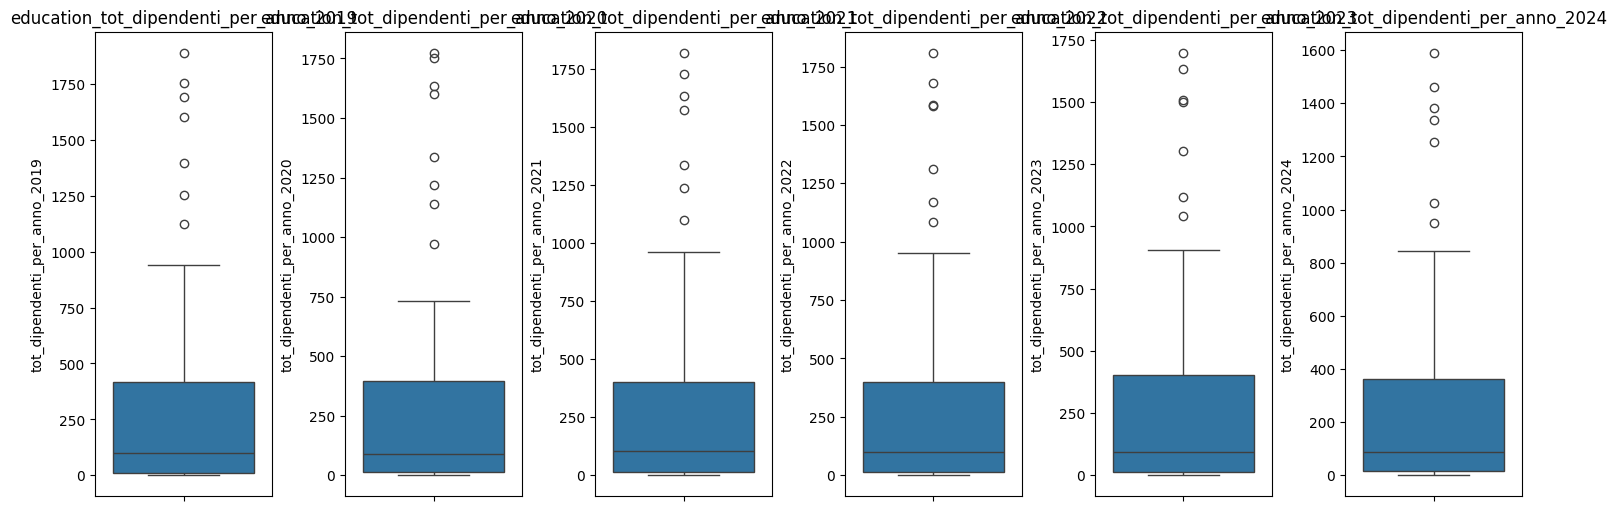

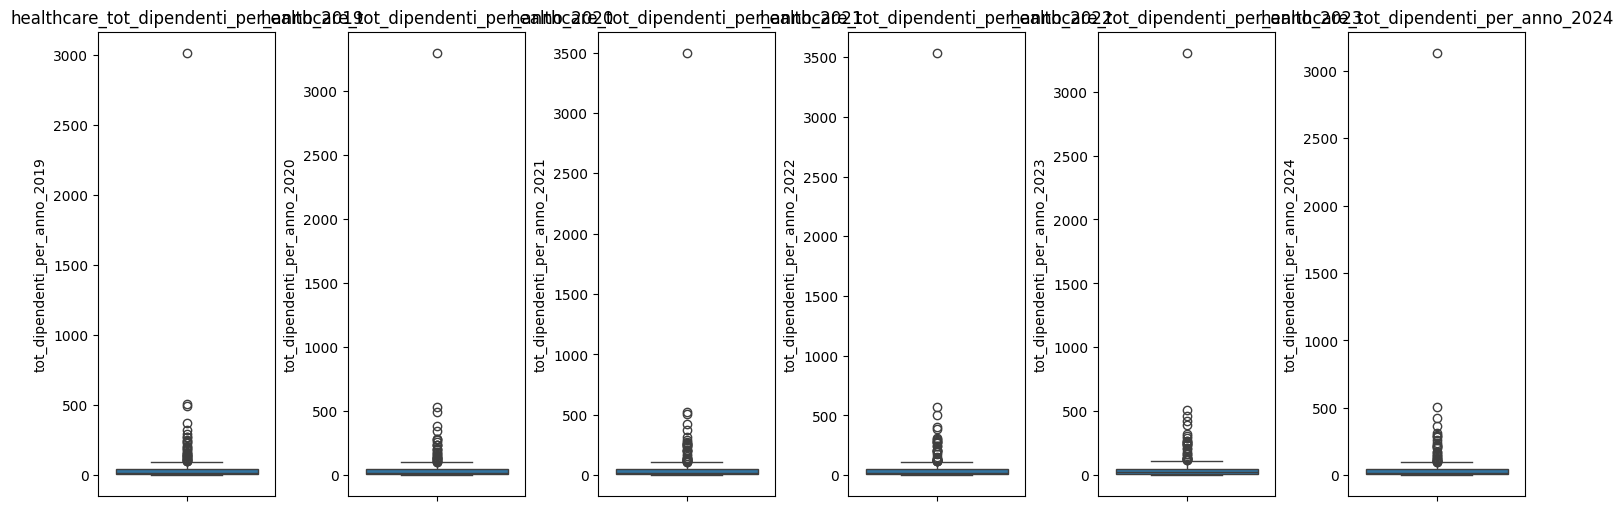

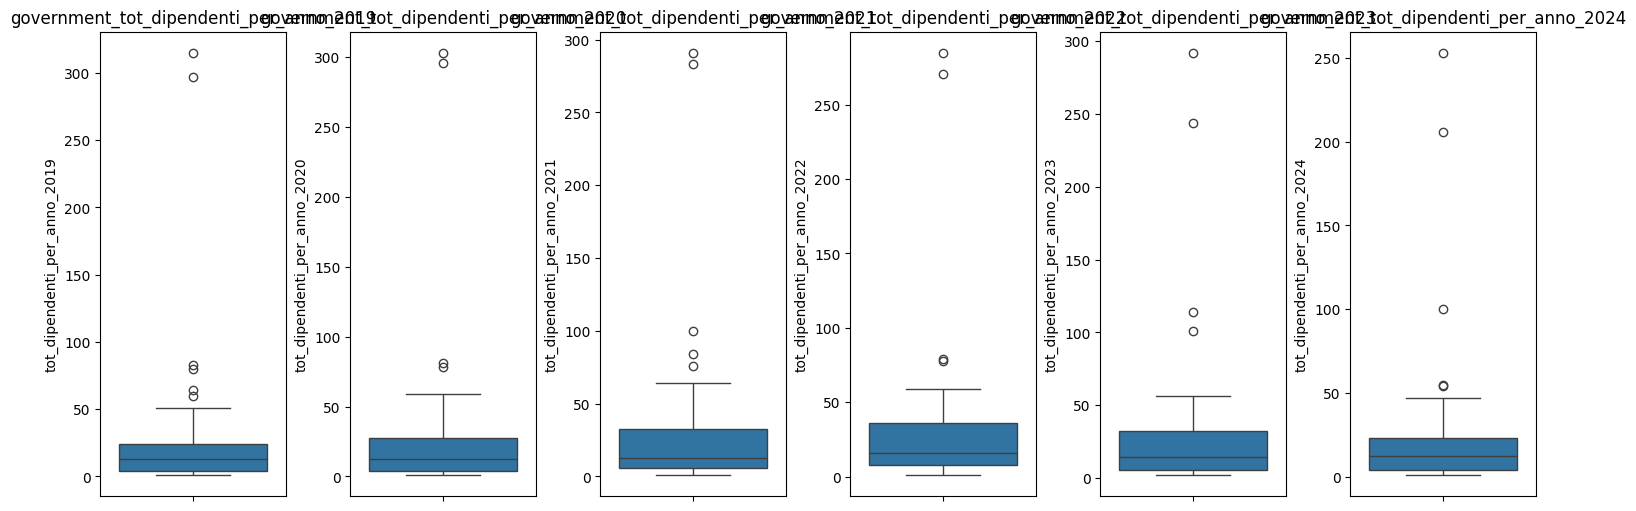

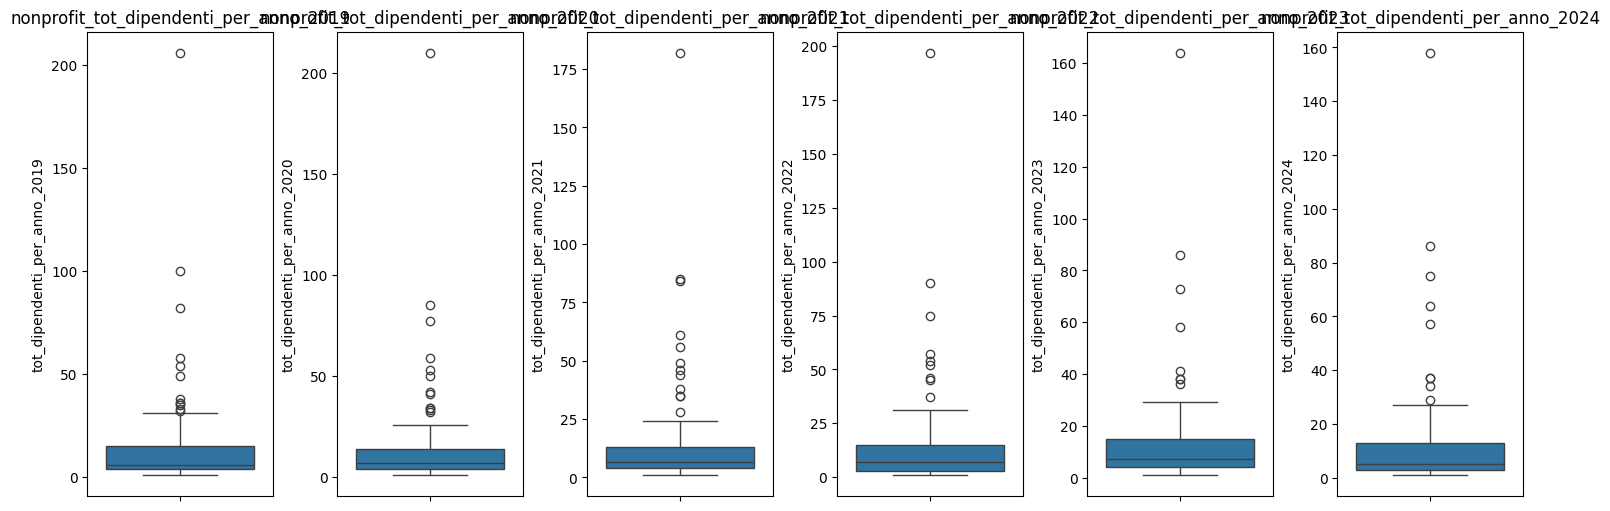

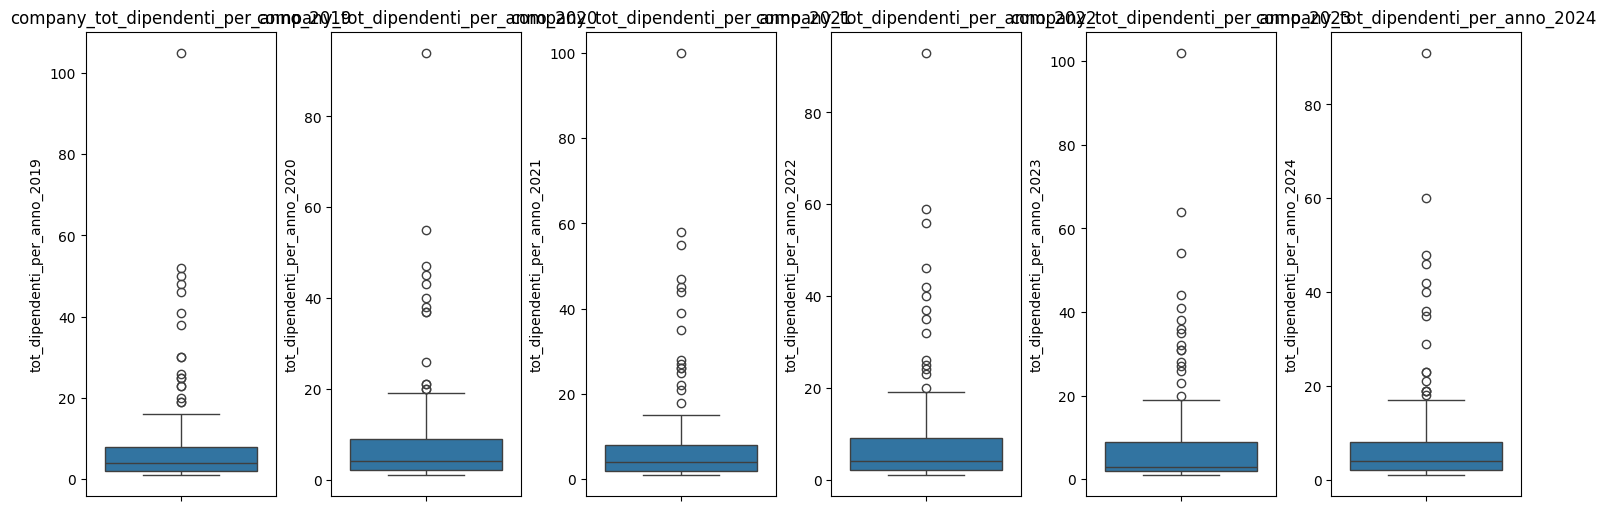

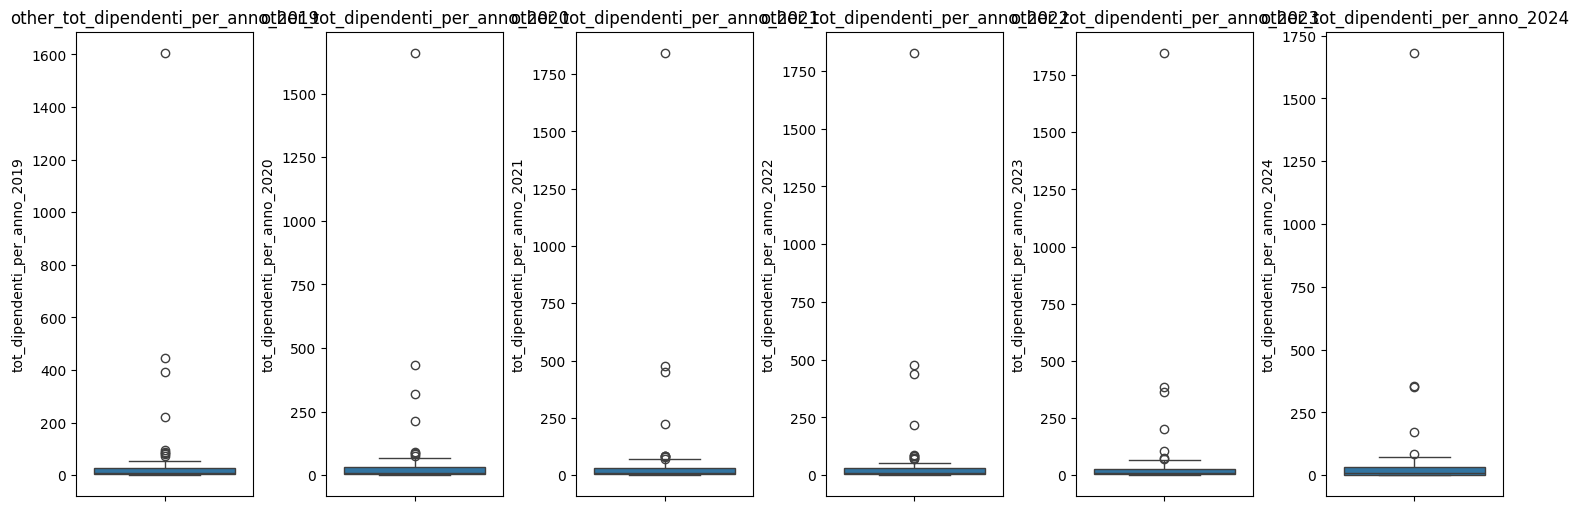

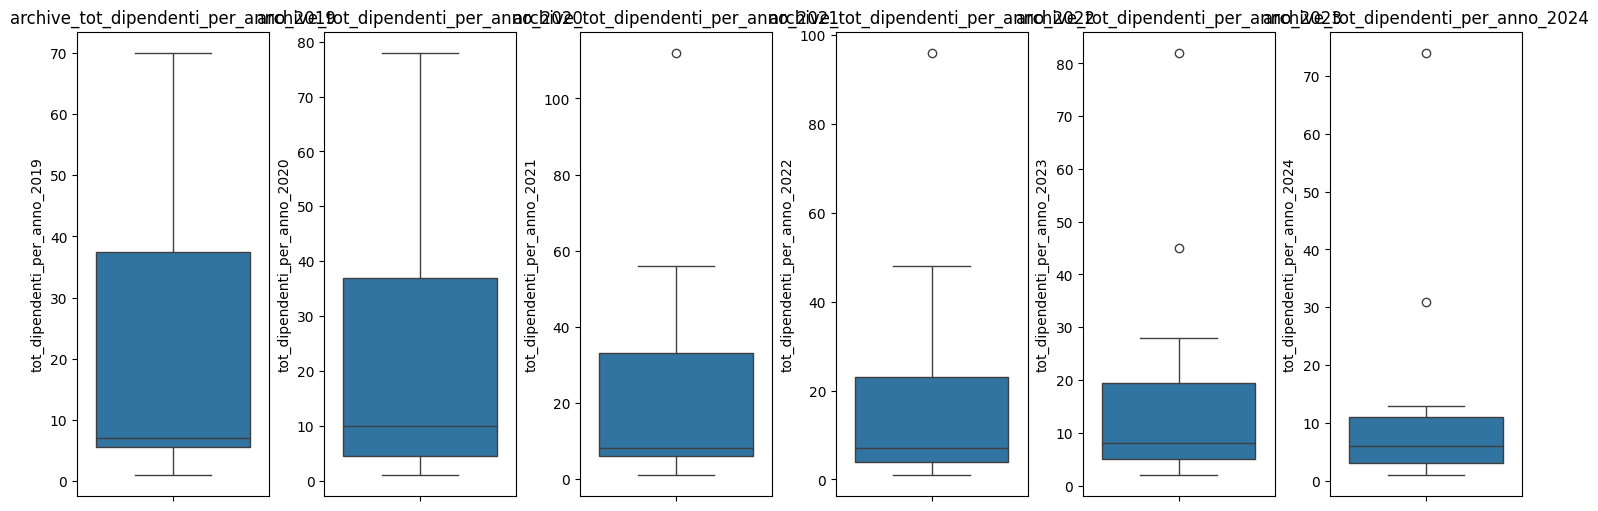

In [92]:
distrib_peoples_data(df_no_nan, cols= columns_tot_dipendenti)
# c'è un fuckton di outliers fantastico

##### Box plot studiosi_entrati

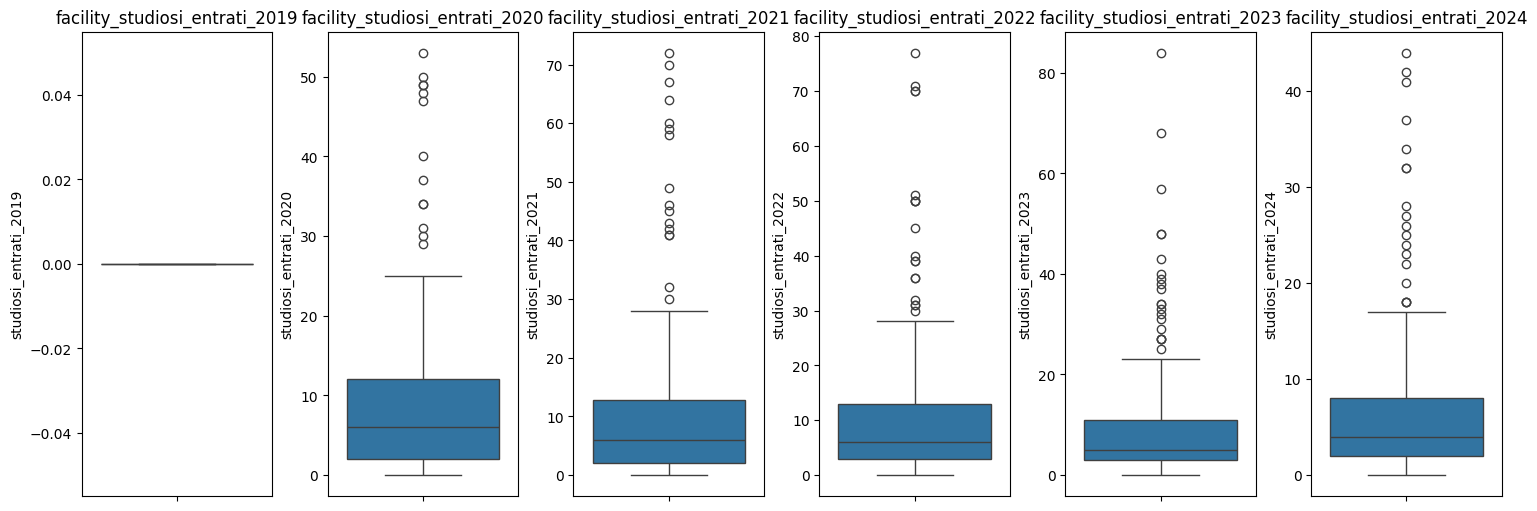

KeyboardInterrupt: 

In [93]:
distrib_peoples_data(df_no_nan, cols = columns_entries)
# Fuckton di outliers pure qua

##### Boxplot studiosi usciti

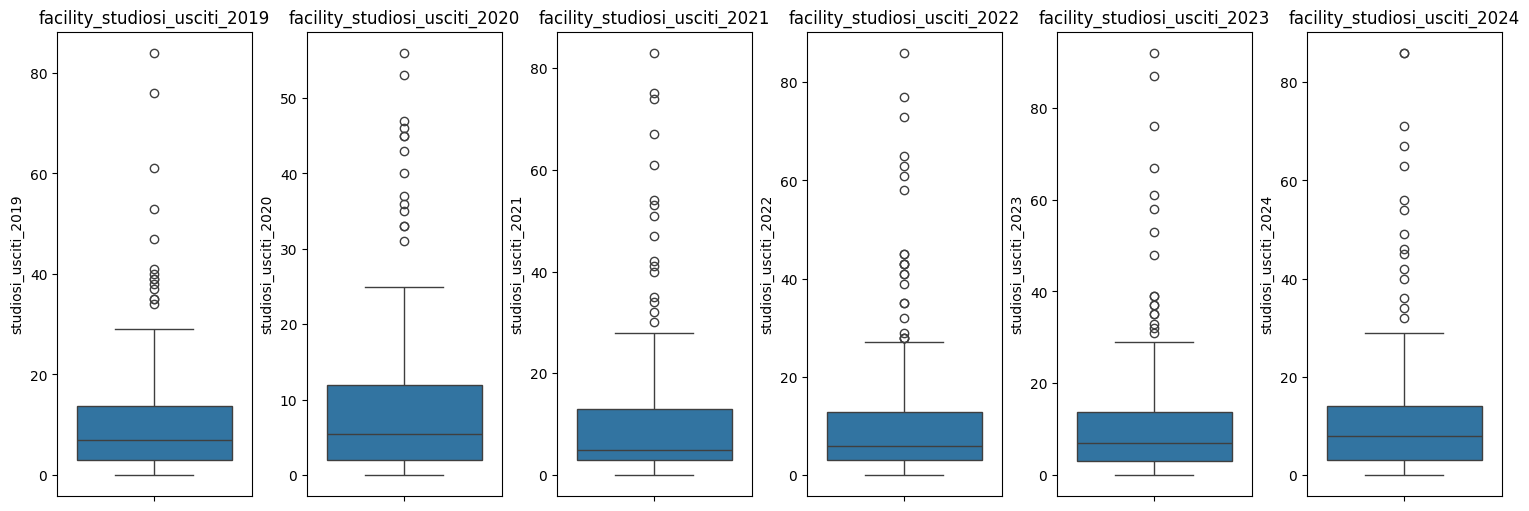

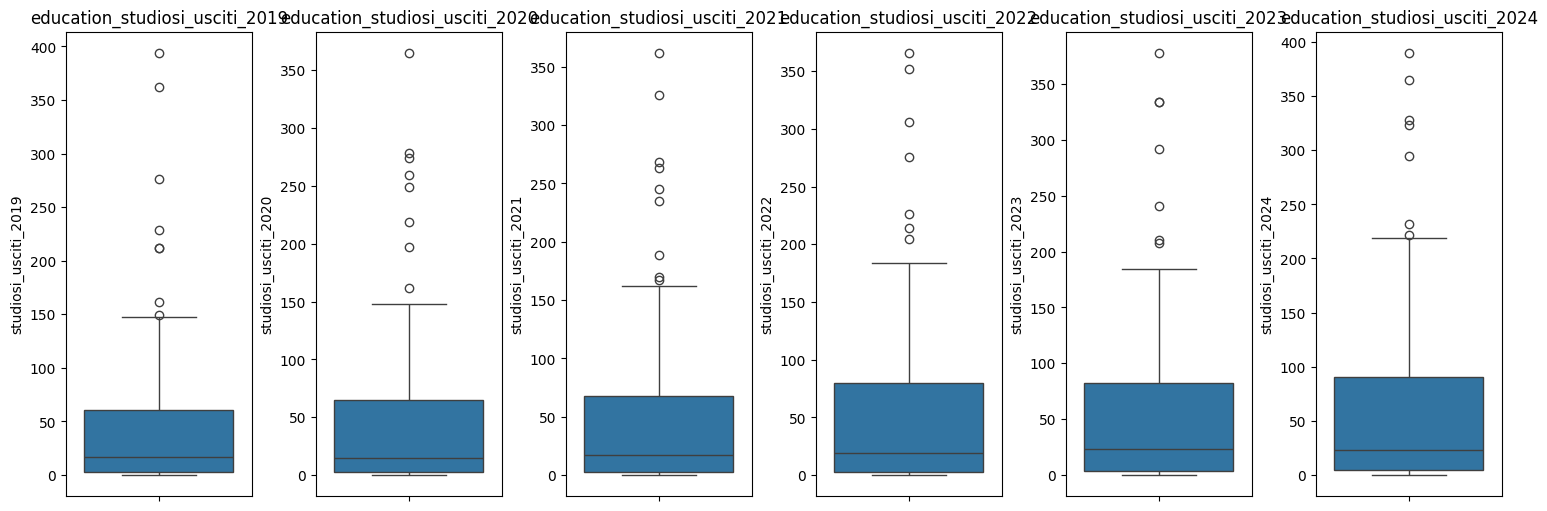

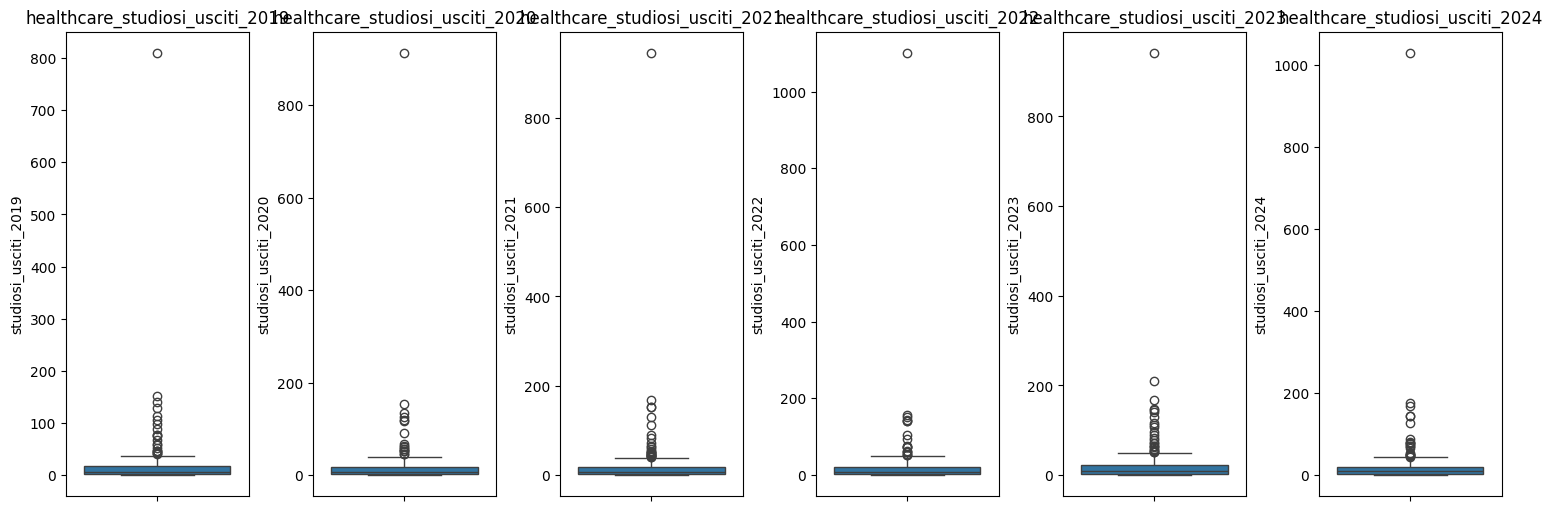

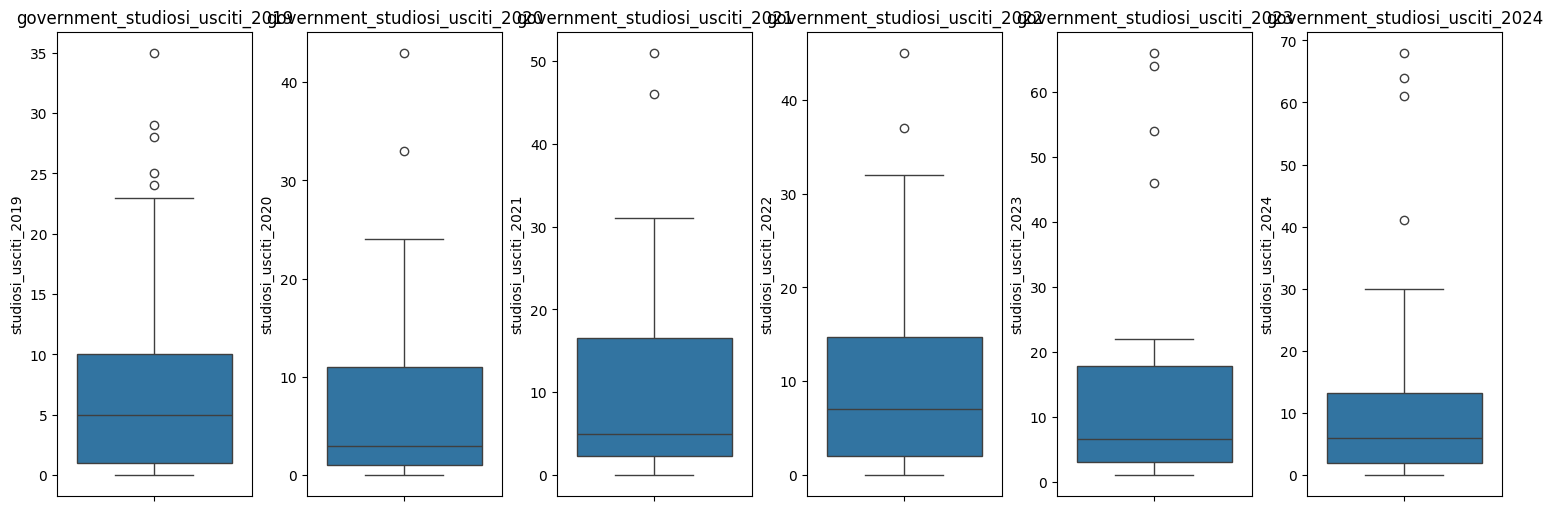

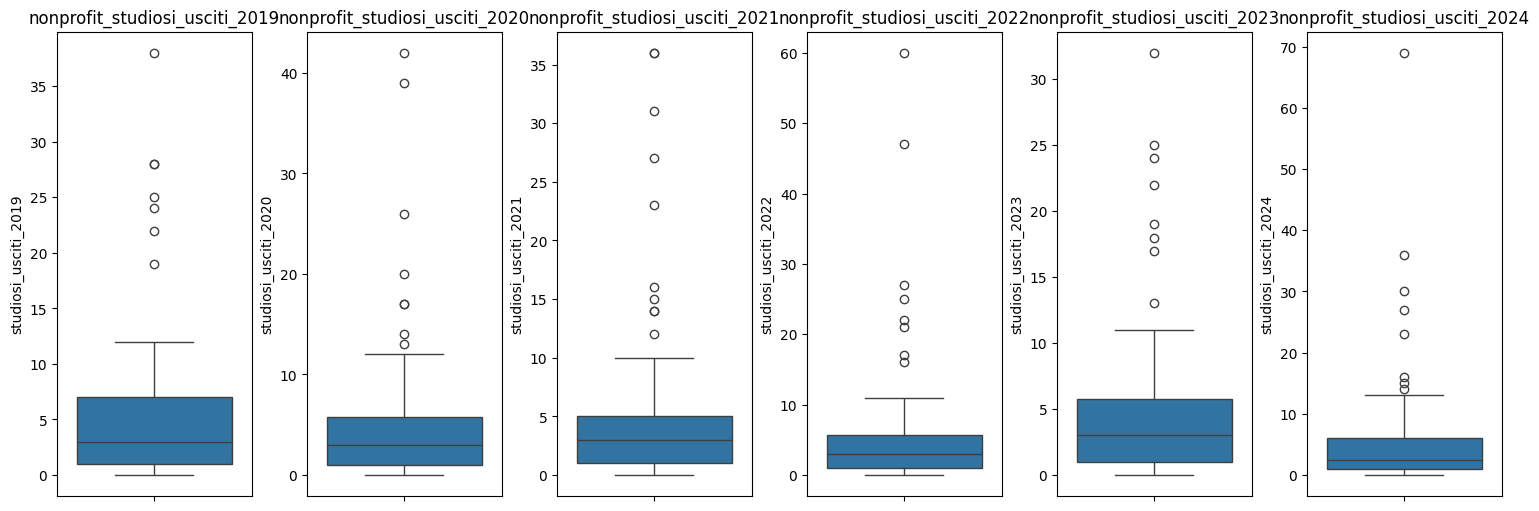

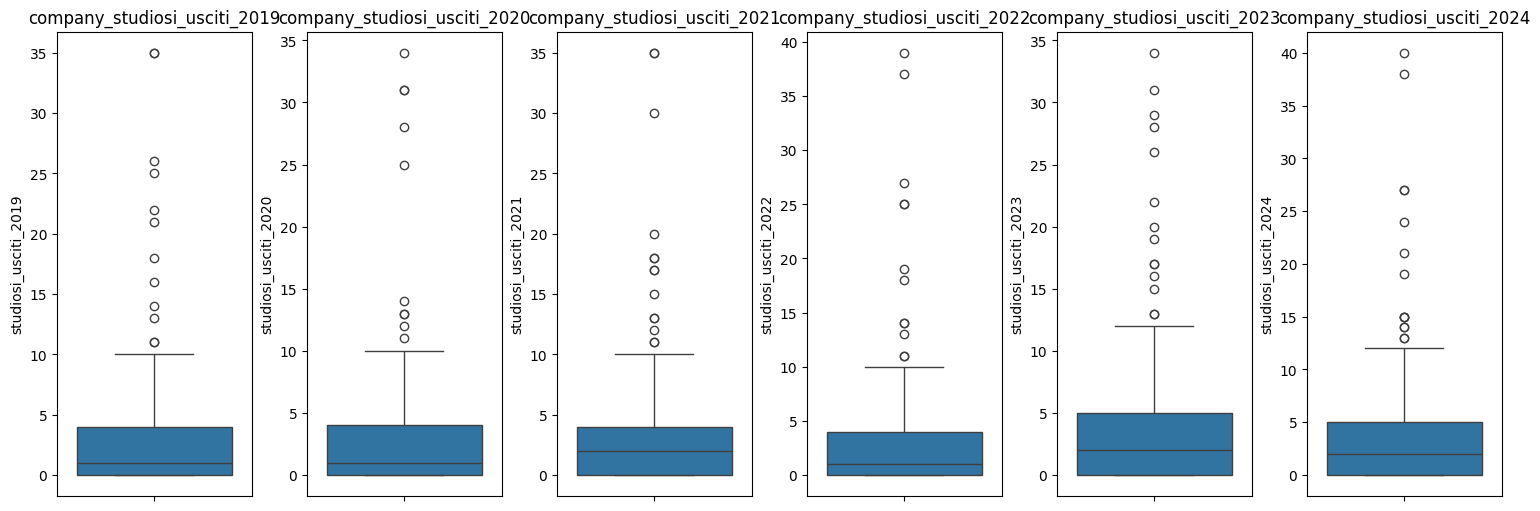

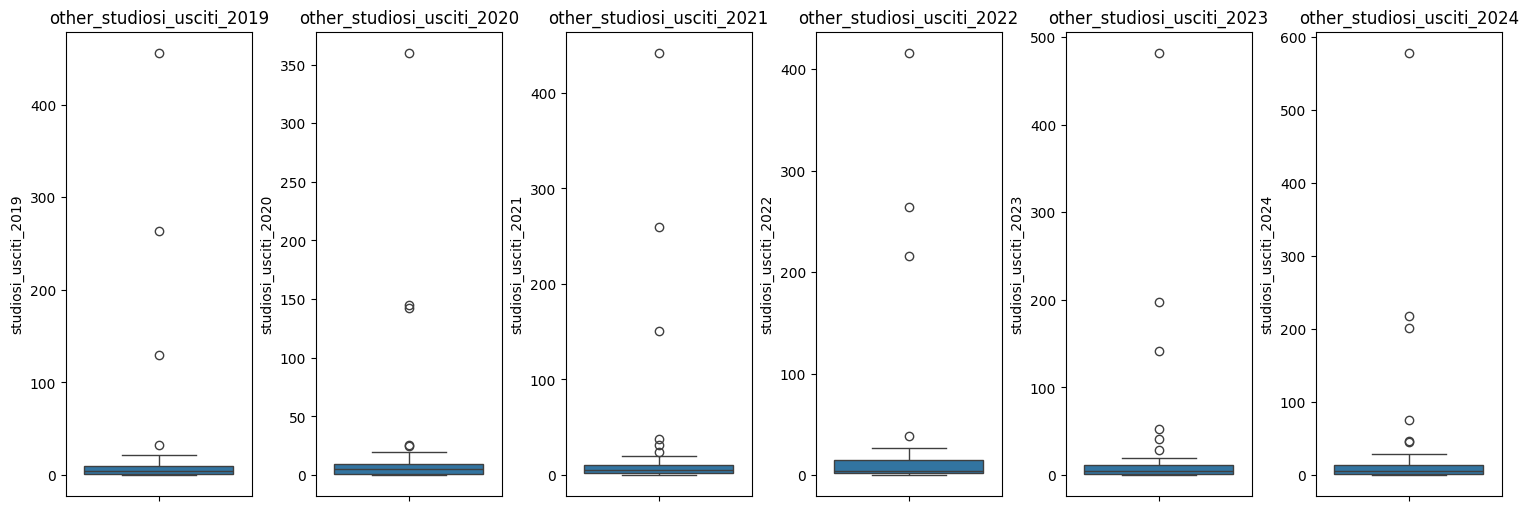

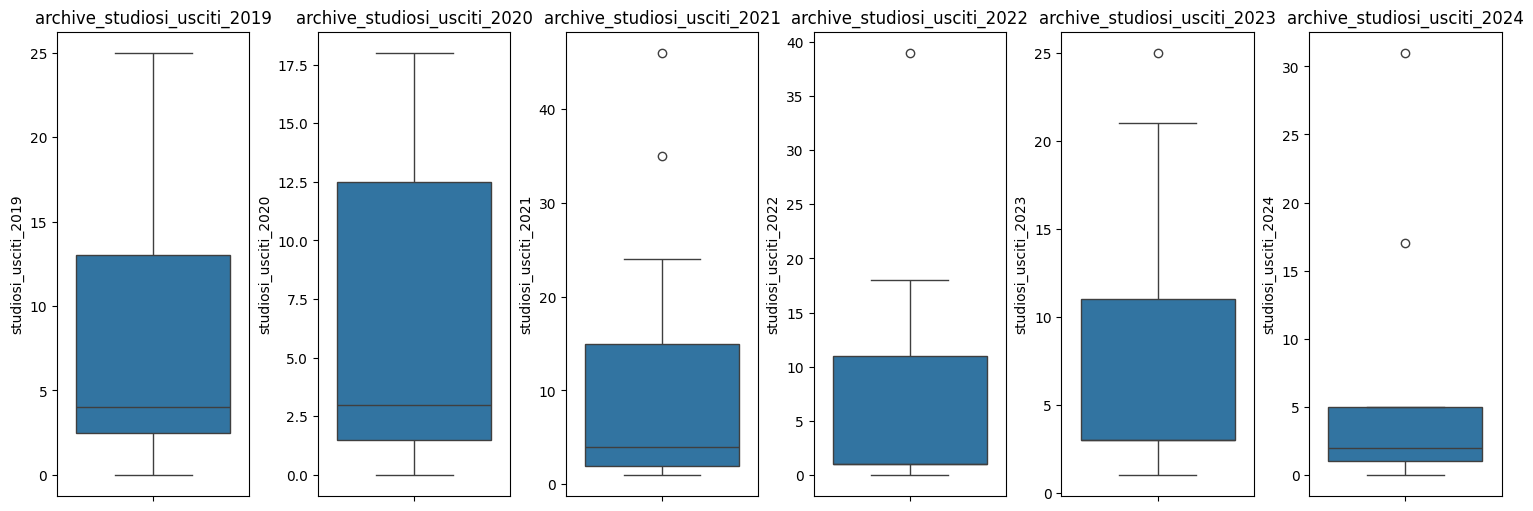

In [ ]:
distrib_peoples_data(df_no_nan, cols = columns_leaving)
# Fuckton di outliers pure qua

##### Altro

In [ ]:
# Coefficiente di variazione per le colonne relative al personale
df_no_nan['tot_dipendenti_cv'] = df_no_nan[columns_tot_dipendenti].std(axis=1) / df_no_nan[columns_tot_dipendenti].mean(axis=1)
df_no_nan['studiosi_entrati_cv'] = df_no_nan[columns_entries].std(axis=1) / df_no_nan[columns_entries].mean(axis=1)
df_no_nan['studiosi_usciti_cv'] = df_no_nan[columns_leaving].std(axis=1) / df_no_nan[columns_leaving].mean(axis=1)

# Aggregato per tipo
cv_per_tipo = df_no_nan.groupby('type')[['tot_dipendenti_cv', 'studiosi_entrati_cv', 'studiosi_usciti_cv']].mean()
print(cv_per_tipo)

            tot_dipendenti_cv  studiosi_entrati_cv  studiosi_usciti_cv
type                                                                  
archive              0.325554             0.894178            0.567822
company              0.357861             1.201714            0.998826
education            0.164000             0.777460            0.459131
facility             0.246143             0.836617            0.599870
government           0.312310             0.870996            0.597072
healthcare           0.259389             0.803971            0.556335
nonprofit            0.363559             0.981527            0.770986
other                0.308650             0.847570            0.637001


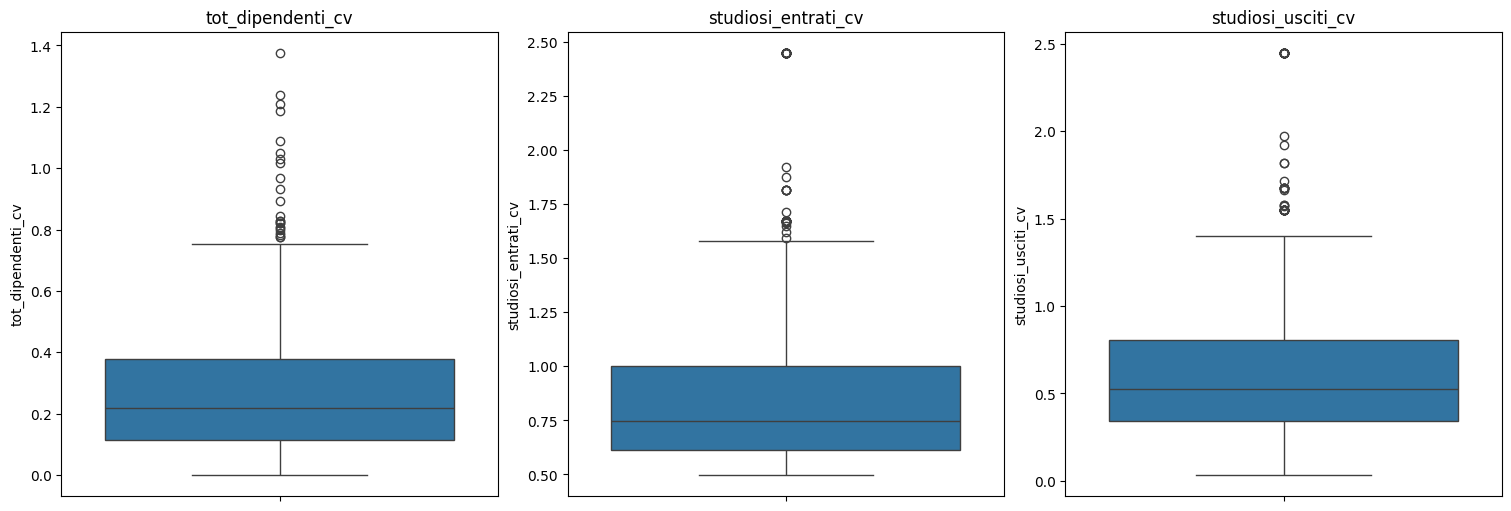

In [ ]:
# Controlliamo i boxplot va
numerical_columns_people = df_no_nan[['tot_dipendenti_cv', 'studiosi_entrati_cv', 'studiosi_usciti_cv']]
columns = 3
rows = 1

fig, axes = plt.subplots(rows, columns, figsize= (15, 5*rows), constrained_layout = True)
axes = axes.flatten()

for i, col in enumerate(numerical_columns_people):
    sns.boxplot(df_no_nan[col], ax = axes[i])
    axes[i].set_title(col)
    
for i in range(len(numerical_columns_people), len(axes)):
    fig.delaxes(axes[i])
    
plt.show()


In [ ]:
def boxplot_by_inst(dataframe):
    for tipo in dataframe['type'].unique():
        colonne = dataframe[dataframe['type'] == tipo][['works_cv', 'cited_cv']]
        columns = 2
        rows = 1

        fig, axes = plt.subplots(rows, columns, figsize=(15, 5*rows), constrained_layout=True)
        axes = axes.flatten()

        for i, col in enumerate(colonne):
            sns.boxplot(colonne[col], ax=axes[i])
            
            axes[i].set_title(f'{tipo}_{col}', fontsize=25)
            axes[i].set_ylabel('Value', fontsize=25)
            axes[i].tick_params(axis='both', labelsize=25)

        for i in range(len(colonne), len(axes)):
            fig.delaxes(axes[i])

        plt.show()

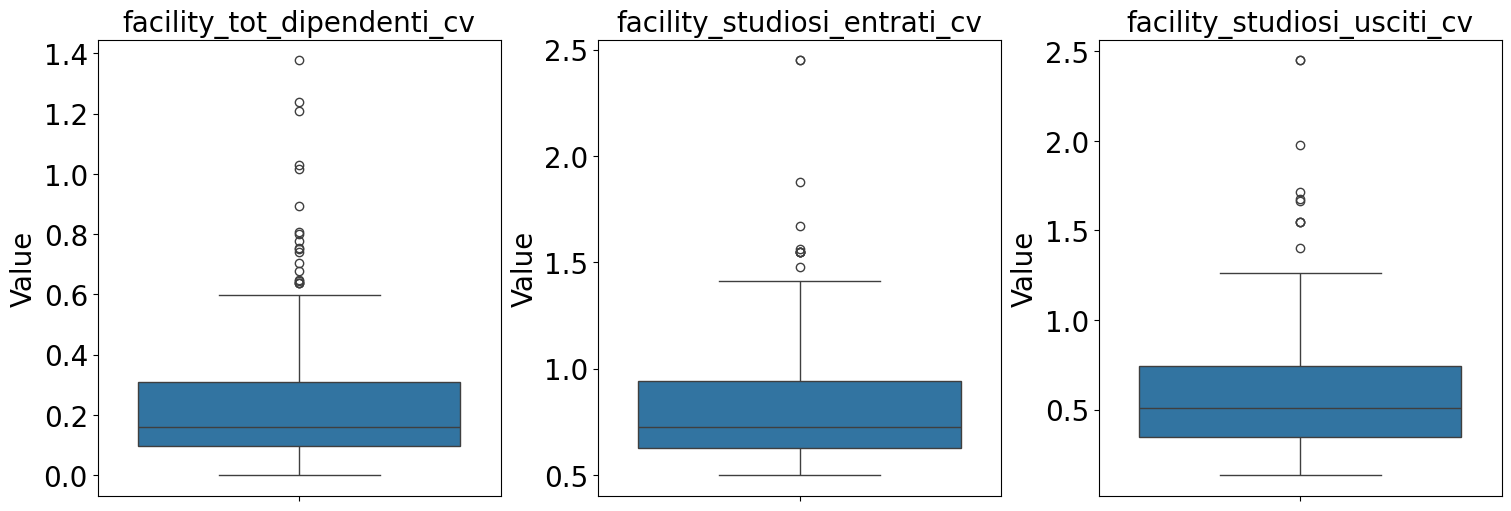

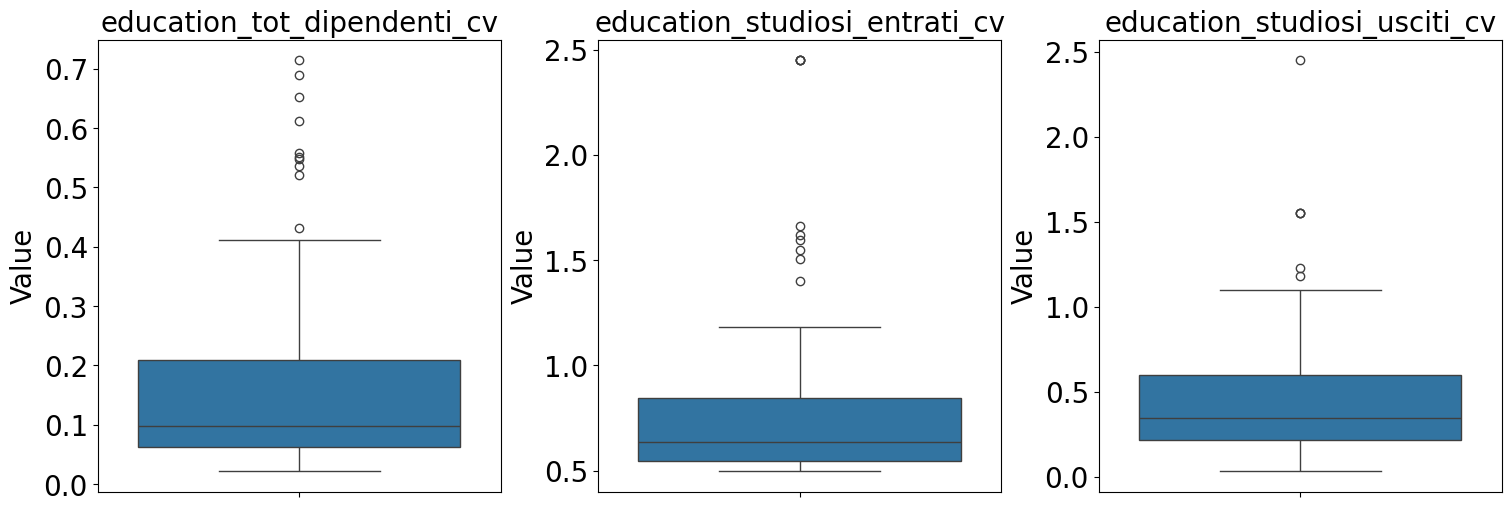

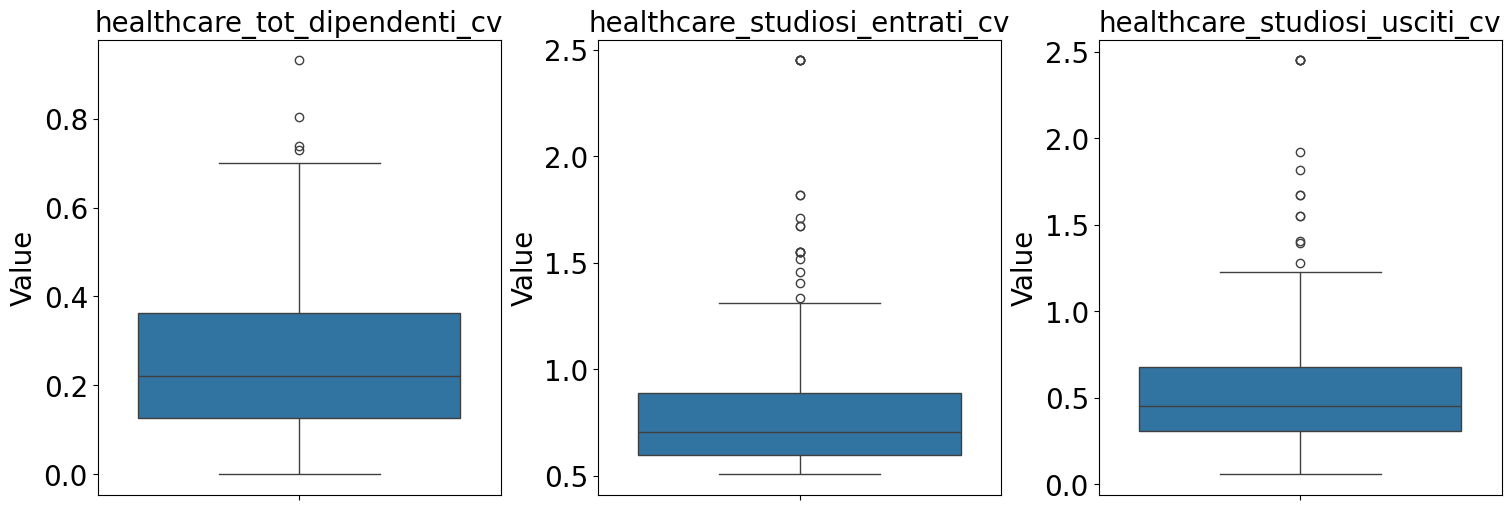

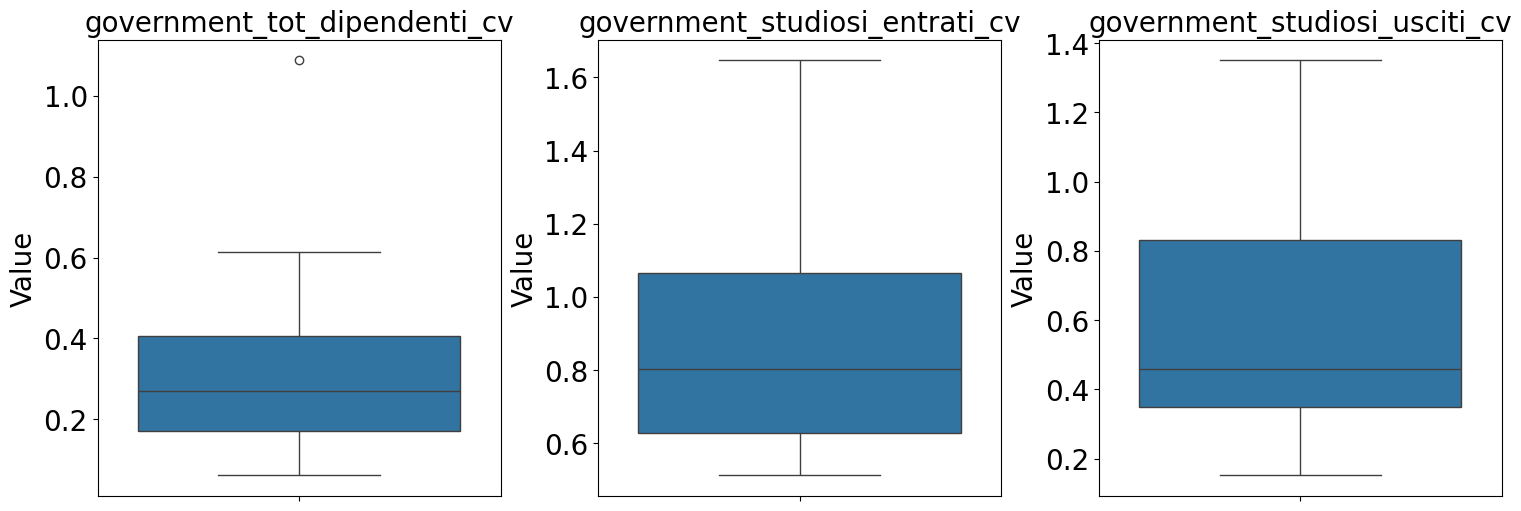

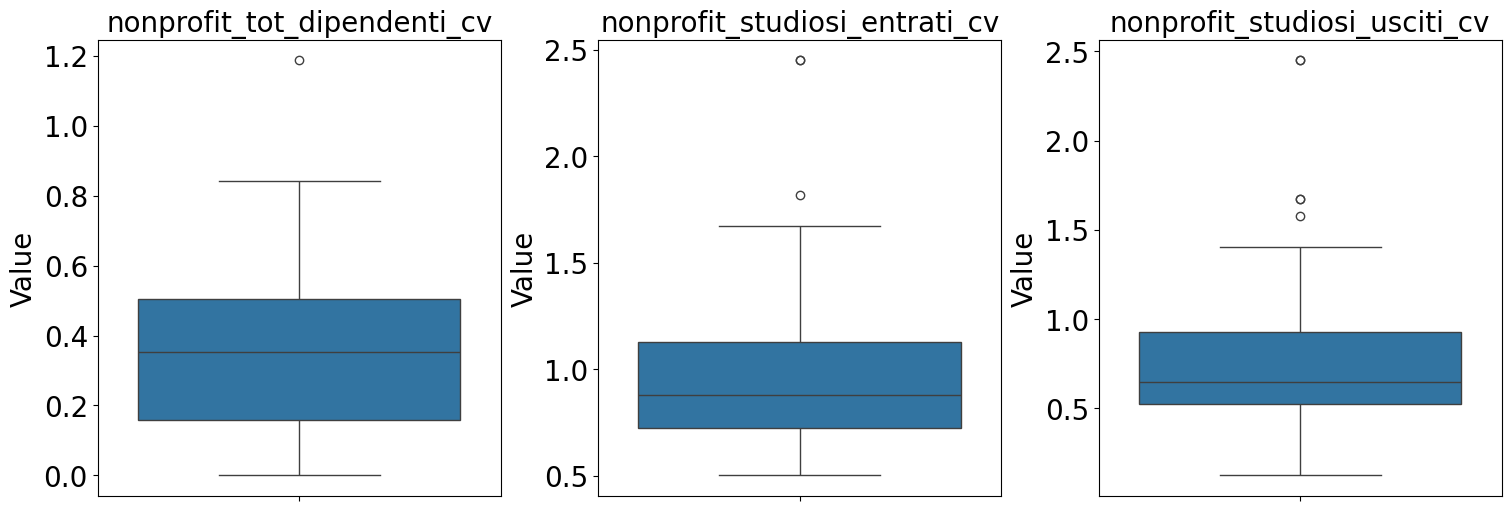

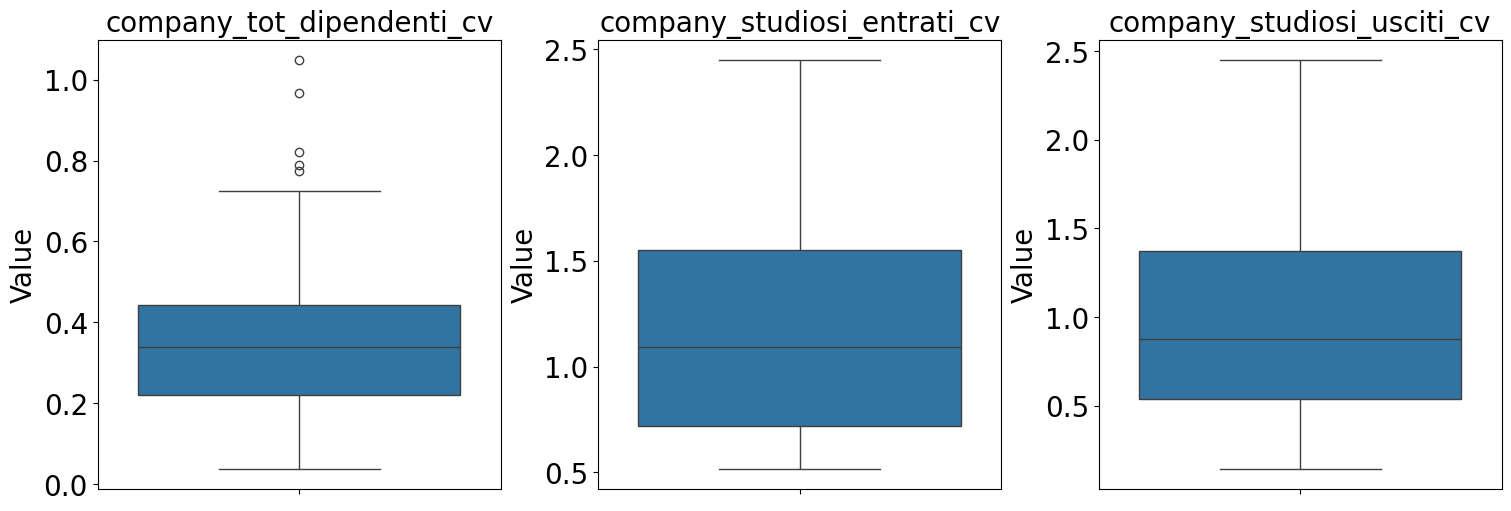

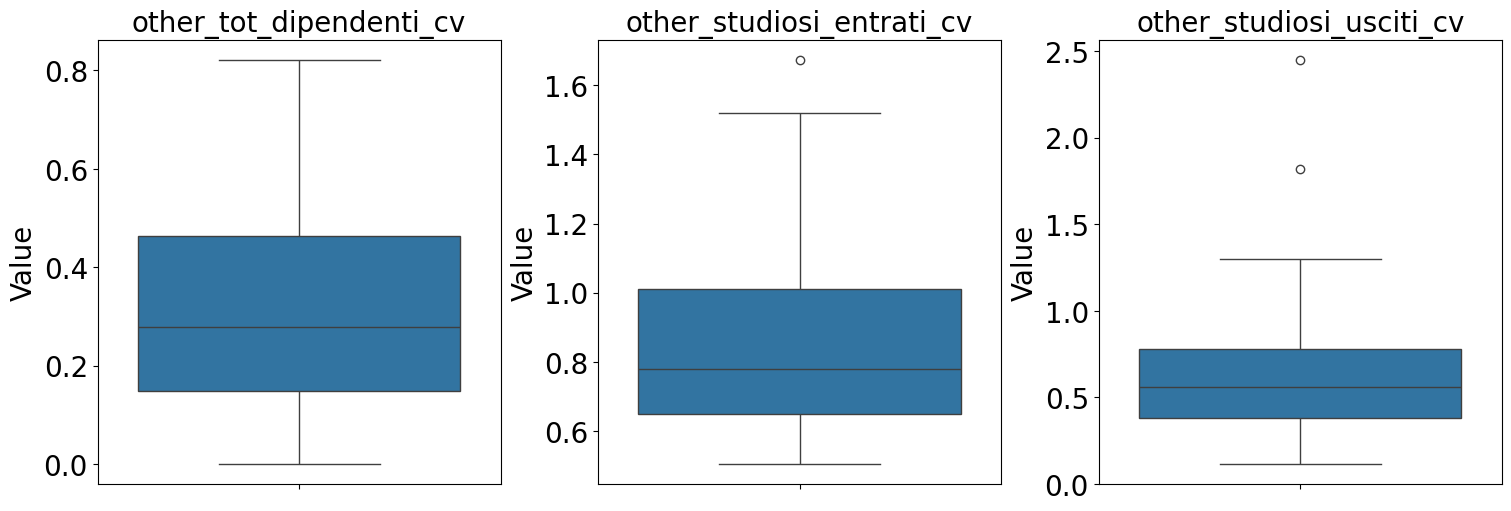

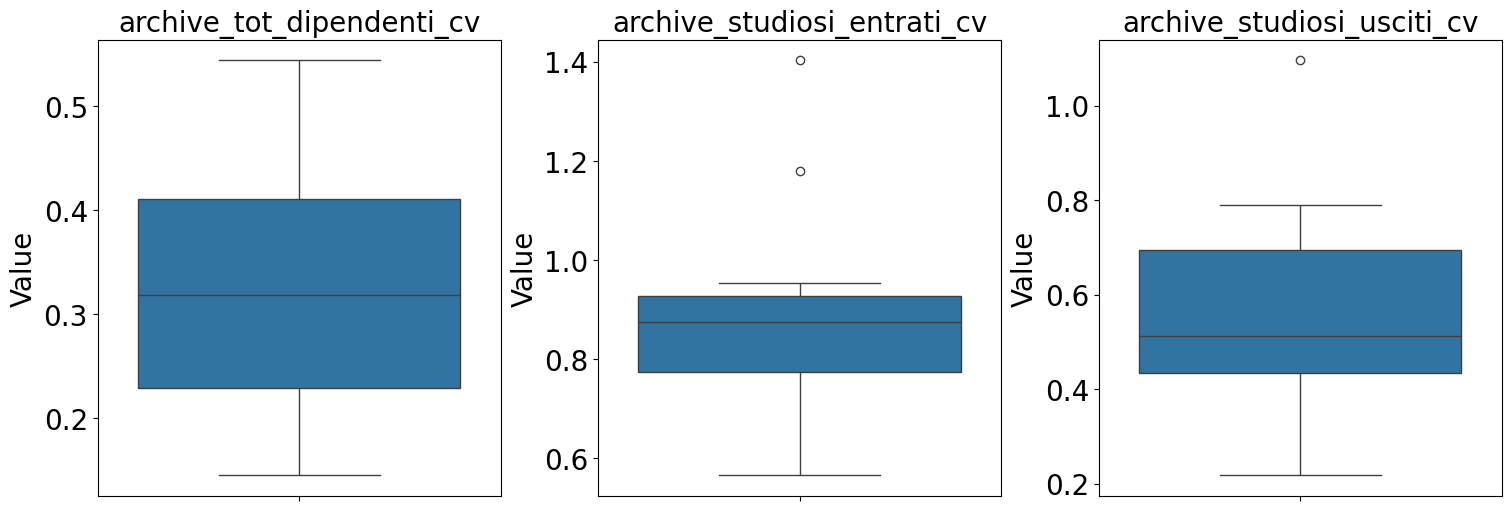

In [ ]:
# Visualizzazione degli outlier sulla base delle istituzioni
def boxplot_by_inst(dataframe):
    for tipo in dataframe['type'].unique():
        colonne = dataframe[dataframe['type'] == tipo][['tot_dipendenti_cv', 'studiosi_entrati_cv', 'studiosi_usciti_cv']]
        columns = 3
        rows = 1

        fig, axes = plt.subplots(rows, columns, figsize= (15, 5*rows), constrained_layout = True)
        axes = axes.flatten()

        for i, col in enumerate(colonne):
            sns.boxplot(colonne[col], ax = axes[i])

            axes[i].set_title(f'{tipo}_{col}', fontsize=20)
            axes[i].set_ylabel('Value', fontsize=20)
            axes[i].tick_params(axis='both', labelsize=20)
            
        for i in range(len(colonne), len(axes)):
            fig.delaxes(axes[i])
            
        plt.show()

boxplot_by_inst(df_no_nan)

Once again, education, facility e healthcare sono quelli con più outlier. La media scartata, probabilmente la mediana è la cosa più semplice, o sennò scaricare altri dati? 
Per ora, riempiamo con la mediana così da poter passare all'outlier detection.

Innanzitutto, eliminiamo le istituzioni a cui mancano due anni di fila, non abbiamo i dati per riempire con la mediana

In [ ]:
def drop_columns_people(dataframe):
    df_copy = dataframe.copy()
    column_types = ['tot_dipendenti_per_anno', 'studiosi_entrati', 'studiosi_usciti']
    years = [2019, 2020, 2021, 2022, 2023, 2024]
    
    for col_type in column_types:
        for year in years[1:-2]:  # [2020, 2021, 2022]
            col = f'{col_type}_{year}'
            prev_col = f'{col_type}_{year - 1}'
            next_col = f'{col_type}_{year + 1}'
            
            mask = (
                df_copy[col].isna() &
                (df_copy[prev_col].isna() | df_copy[next_col].isna())
            )
            df_copy = df_copy.loc[~mask]
        
        # Gestione separata per il 2023 (ultimo anno)
        col_2023 = f'{col_type}_2023'
        mask_2023 = df_copy[col_2023].isna()
        df_copy = df_copy.loc[~mask_2023]
    
    return df_copy

In [ ]:
df_copy_people = drop_columns_people(df)

In [ ]:
def fill_nan_people(dataframe):
    df_filled = dataframe.copy()
    column_types = ['tot_dipendenti_per_anno', 'studiosi_entrati', 'studiosi_usciti']
    years = [2019, 2020, 2021, 2022, 2023, 2024]
    
    for col_type in column_types:
        for year in years:
            col_name = f'{col_type}_{year}'
            if col_name not in df_filled.columns:
                continue
            
            else:
                # Riempi con mediana degli anni adiacenti
                prev_col = f'{col_type}_{year - 1}'
                next_col = f'{col_type}_{year + 1}'
                if prev_col in df_filled.columns and next_col in df_filled.columns:
                    median_vals = df_filled[[prev_col, next_col]].median(axis=1)
                    df_filled[col_name] = df_filled[col_name].fillna(median_vals)
    
    return df_filled


In [ ]:
df_filled = fill_nan_people(df_copy_people)

In [ ]:
# Eliminiamo le colonne relative al 2019
colonne_2019 = df_filled.filter(regex=r"2019").columns.tolist()
df_filled = df_filled.drop(colonne_2019, axis = 1)

In [ ]:
per_missing_df_filled = df_filled.isnull().sum() * 100/len(df_filled)
print(per_missing_df_filled)

nome_istituzione                0.000000
city                            0.000000
regione                         0.000000
macroarea                       0.000000
type                            0.000000
works_count_2023                0.000000
cited_by_count_2023             0.000000
works_count_2022                0.000000
cited_by_count_2022             0.000000
works_count_2021                0.000000
cited_by_count_2021             0.000000
works_count_2020                0.000000
cited_by_count_2020             0.000000
roles                           0.000000
tot_dipendenti_per_anno_2020    0.000000
studiosi_usciti_2020            0.000000
studiosi_entrati_2020           0.000000
tot_dipendenti_per_anno_2021    0.000000
studiosi_usciti_2021            0.000000
studiosi_entrati_2021           0.000000
tot_dipendenti_per_anno_2022    0.000000
studiosi_usciti_2022            0.000000
studiosi_entrati_2022           0.000000
tot_dipendenti_per_anno_2023    0.000000
studiosi_usciti_

In [ ]:
df_filled.shape

(1008, 51)

In [ ]:
df_final = df_filled.dropna()
df_final.shape

(958, 51)

In [ ]:
df_final

,nome_istituzione,city,regione,macroarea,type,works_count_2023,cited_by_count_2023,works_count_2022,cited_by_count_2022,works_count_2021,cited_by_count_2021,works_count_2020,cited_by_count_2020,roles,tot_dipendenti_per_anno_2020,studiosi_usciti_2020,studiosi_entrati_2020,tot_dipendenti_per_anno_2021,studiosi_usciti_2021,studiosi_entrati_2021,tot_dipendenti_per_anno_2022,studiosi_usciti_2022,studiosi_entrati_2022,tot_dipendenti_per_anno_2023,studiosi_usciti_2023,studiosi_entrati_2023,tot_dipendenti_per_anno_2024,studiosi_usciti_2024,studiosi_entrati_2024,2020_Health Sciences,2020_Life Sciences,2020_Social Sciences,2020_Physical Sciences,2021_Health Sciences,2021_Life Sciences,2021_Social Sciences,2021_Physical Sciences,2022_Health Sciences,2022_Life Sciences,2022_Social Sciences,2022_Physical Sciences,2023_Health Sciences,2023_Life Sciences,2023_Social Sciences,2023_Physical Sciences,2024_Health Sciences,2024_Life Sciences,2024_Social Sciences,2024_Physical Sciences,roles_cleaned,num_roles
0,Institute of Neurological Sciences,Mangone,Calabria,Sud,facility,117.0,960.0,94.0,2851.0,136.0,2447.0,152.0,6189.0,[institution],50.0,35.0,29.0,28.0,20.0,13.0,22.0,12.0,14.0,24.0,11.0,14.0,20.0,10.0,7.0,74.81,22.22,1.48,1.48,73.04,21.74,4.35,0.87,70.37,19.75,8.64,1.23,63.27,29.59,4.08,3.06,65.71,23.81,5.71,4.76,[institution],1
1,University of Siena,Siena,Tuscany,Centro,education,3034.0,21889.0,2844.0,40025.0,2662.0,53416.0,2719.0,75996.0,"[funder, institution]",394.0,63.0,52.0,400.0,77.0,69.0,398.0,102.0,75.0,438.0,151.0,142.0,349.0,93.0,62.0,45.11,17.44,14.16,23.30,43.66,17.15,16.17,23.02,44.97,17.19,13.95,23.89,42.75,16.65,15.60,25.01,45.32,15.95,15.75,22.97,"[funder, institution]",2
2,IRCCS Ospedale San Raffaele,Milan,Lombardy,Nord,healthcare,1629.0,16301.0,1426.0,34961.0,1270.0,38226.0,1163.0,49243.0,[institution],280.0,90.0,123.0,376.0,130.0,186.0,385.0,141.0,139.0,425.0,210.0,181.0,313.0,126.0,98.0,82.78,13.71,2.00,1.50,79.04,17.56,1.42,1.98,73.76,21.86,2.36,2.03,75.72,19.89,2.48,1.92,72.41,23.45,1.57,2.57,[institution],1
3,Bambino Gesù Children's Hospital,Rome,Lazio,Centro,healthcare,1627.0,14612.0,1804.0,31688.0,1686.0,39876.0,1542.0,55282.0,[institution],232.0,28.0,25.0,231.0,28.0,27.0,244.0,59.0,41.0,209.0,32.0,24.0,215.0,46.0,38.0,66.37,28.78,2.15,2.70,65.48,28.03,4.12,2.37,66.84,27.35,3.90,1.92,69.99,25.60,2.28,2.13,69.21,25.67,2.96,2.16,[institution],1
4,University of Florence,Florence,Tuscany,Centro,education,7698.0,66448.0,7750.0,100752.0,7537.0,131602.0,7306.0,173527.0,"[funder, institution, publisher]",1141.0,219.0,177.0,1098.0,189.0,176.0,1083.0,205.0,174.0,1043.0,210.0,165.0,949.0,222.0,116.0,32.44,17.50,15.44,34.62,31.94,17.75,15.81,34.51,32.98,16.92,16.39,33.72,33.15,15.82,16.33,34.70,31.83,14.80,17.52,35.85,"[funder, institution, publisher]",3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1257,Cereal Research Centre,Foggia,Apulia,Sud,facility,372.0,2907.0,326.0,4800.0,329.0,6916.0,325.0,11865.0,[institution],82.0,18.0,18.0,80.0,25.0,16.0,72.0,24.0,17.0,69.0,16.0,21.0,66.0,26.0,13.0,15.60,61.35,2.13,20.92,12.36,68.16,2.62,16.85,14.24,59.72,3.82,22.22,13.48,61.13,3.45,21.94,8.90,64.77,2.49,23.84,[institution],1
1258,Ospedale Pediatrico Giovanni XXIII,Bari,Apulia,Sud,healthcare,167.0,1308.0,182.0,1749.0,152.0,2241.0,145.0,4627.0,[institution],21.0,10.0,13.0,24.0,10.0,13.0,18.0,1.0,4.0,29.0,13.0,12.0,26.0,16.0,10.0,75.86,18.97,2.59,2.59,80.33,13.93,3.28,2.46,74.36,21.79,2.56,1.28,77.54,19.57,1.45,1.45,77.54,16.67,2.90,2.90,[institution],1
1259,Ospedale San Bortolo,Vicenza,Veneto,Nord,healthcare,328.0,3031.0,312.0,2998.0,280.0,4931.0,280.0,7011.0,[institution],30.0,4.0,2.0,32.0,6.0,6.0,33.0,12.0,7.0,27.0,7.0,6.0,31.0,15.0,11.0,85.17,10.27,1.90,2.66,88.55,7.25,1.53,2.67,87.81,10.04,1.08,1.08,83.84,10.44,1.35,4.38,84.62,9.79,2.10,3.50,[institution],1
1260,Telethon Fo

In [ ]:
# Correlation analysis: DA RUNNARE PRIMA DELLE TRASFORMAZIONI
'''
corr = df.corr(numeric_only=True)

mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr,
    mask=mask,
    cmap="RdBu_r",
    center=0,
    annot=False,
    linewidths=0.5
)
plt.title("Matrice di correlazione (triangolo inferiore)")
plt.show()
'''
# Ha senso tenendo conto che ho pienato i valori mancanti con quelli accanto💀


'\ncorr = df.corr(numeric_only=True)\n\nmask = np.triu(np.ones_like(corr, dtype=bool))\n\nplt.figure(figsize=(14, 12))\nsns.heatmap(\n    corr,\n    mask=mask,\n    cmap="RdBu_r",\n    center=0,\n    annot=False,\n    linewidths=0.5\n)\nplt.title("Matrice di correlazione (triangolo inferiore)")\nplt.show()\n'

In [ ]:
df_final.to_csv('df_understanding_analysis.csv', index=False)